<a href="https://colab.research.google.com/github/sadiashatabdi/kidney-disease-machine-learning-xai/blob/main/Balanced_Kidney_disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Import necessary Library**

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from scipy.stats import kstest
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, auc
from collections import Counter
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats
from scipy.stats import chi2_contingency
from scipy.stats import f_oneway
from scipy.stats import ttest_ind

# **Load the Dataset**

In [ ]:
!gdown --id 1Z7XZKtDUR-pwcHMvFouqS0QT7eX5iLGt

/usr/local/lib/python3.11/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1Z7XZKtDUR-pwcHMvFouqS0QT7eX5iLGt
To: /content/Balanced_Chronic_Kidney_Disease_data.csv
100% 1.87M/1.87M [00:00<00:00, 80.7MB/s]


In [ ]:
dataset=pd.read_csv('/content/Balanced_Chronic_Kidney_Disease_data.csv')
dataset.head()

,PatientID,Age,Gender,Ethnicity,SocioeconomicStatus,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,...,Itching,QualityOfLifeScore,HeavyMetalsExposure,OccupationalExposureChemicals,WaterQuality,MedicalCheckupsFrequency,MedicationAdherence,HealthLiteracy,Diagnosis,DoctorInCharge
0,979,48,1,2,1,0,27.368856,0,10.567042,2.726305,...,5.275902,20.500955,1,0,0,2.539167,2.242007,7.001788,0,Confidential
1,81,30,0,0,1,2,22.458444,0,2.565535,9.084635,...,0.231060,51.745590,0,0,1,1.959213,6.258367,1.409766,0,Confidential
2,1444,49,1,2,2,3,26.199886,0,10.194849,3.114954,...,1.315039,74.577343,0,0,0,0.669826,3.473029,0.875867,0,Confidential
3,364,82,1,0,2,1,17.754303,0,0.053363,0.956486,...,2.914219,30.309278,0,0,1,1.503674,8.270212,1.908300,1,Confidential
4,1622,49,1,0,2,1,35.767240,0,6.451568,6.833608,...,0.562846,90.692884,0,0,0,3.250583,0.663062,3.362933,0,Confidential


# **Unsupervised Learning**

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

# **Preprocess**

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Assuming df is already defined with the dataset
# Split the features into categorical and numerical
categorical_features = dataset.select_dtypes(include=['object']).columns
numerical_features = dataset.select_dtypes(include=['int64', 'float64']).columns

# Standard scaling for numerical features only
scaler = StandardScaler()
scaled_numerical_data = scaler.fit_transform(dataset[numerical_features])

# One-hot encoding for categorical features only
# The 'sparse' parameter is removed for compatibility with older versions
# If using a newer version, you might need to adjust this
encoder = OneHotEncoder(drop='first')
encoded_categorical_data = encoder.fit_transform(dataset[categorical_features]).toarray()
# toarray() is added to convert the sparse matrix to a dense array if needed

# Concatenate the scaled numerical and encoded categorical data
processed_data = np.hstack([scaled_numerical_data, encoded_categorical_data])

# Convert to DataFrame with appropriate column names
final_columns = numerical_features.tolist() + encoder.get_feature_names_out(categorical_features).tolist()
processed_data_dataset = pd.DataFrame(processed_data, columns=final_columns)

# Save processed data to CSV
processed_data_dataset.to_csv('processed_data.csv', index=False)

# Display the first few rows of the processed DataFrame
processed_data_dataset.head()

,PatientID,Age,Gender,Ethnicity,SocioeconomicStatus,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,...,MuscleCramps,Itching,QualityOfLifeScore,HeavyMetalsExposure,OccupationalExposureChemicals,WaterQuality,MedicalCheckupsFrequency,MedicationAdherence,HealthLiteracy,Diagnosis
0,0.056124,-0.322470,1.011882,1.280871,-0.016554,-1.882872,0.047447,-0.610209,0.103396,-0.864409,...,-1.529422,0.223262,-1.016245,4.700097,-0.359593,-0.516559,0.476421,-0.941430,0.618922,-1.0
1,-1.665590,-1.220723,-0.988258,-0.729477,-0.016554,0.256548,-0.642045,-0.610209,-1.293563,1.384315,...,-0.069619,-1.544701,0.125950,-0.212762,-0.359593,1.935888,-0.025650,0.444676,-1.247305,-1.0
2,0.947658,-0.272567,1.011882,1.280871,1.244893,1.326258,-0.116693,-0.610209,0.038416,-0.726958,...,0.253894,-1.164821,0.960600,-0.212762,-0.359593,-0.516559,-1.141883,-0.516586,-1.425483,-1.0
3,-1.123001,1.374230,1.011882,-0.729477,1.244893,-0.813162,-1.302574,-0.610209,-1.732156,-1.490334,...,-0.978539,-0.604389,-0.657686,-0.212762,-0.359593,1.935888,-0.420014,1.138994,-1.080929,1.0
4,1.288933,-0.272567,1.011882,-0.729477,1.244893,-0.813162,1.226699,-0.610209,-0.615112,0.588203,...,-1.338643,-1.428427,1.549728,-0.212762,-0.359593,-0.516559,1.092300,-1.486347,-0.595474,-1.0


In [ ]:
processed_data_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3048 entries, 0 to 3047
Data columns (total 53 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   PatientID                      3048 non-null   float64
 1   Age                            3048 non-null   float64
 2   Gender                         3048 non-null   float64
 3   Ethnicity                      3048 non-null   float64
 4   SocioeconomicStatus            3048 non-null   float64
 5   EducationLevel                 3048 non-null   float64
 6   BMI                            3048 non-null   float64
 7   Smoking                        3048 non-null   float64
 8   AlcoholConsumption             3048 non-null   float64
 9   PhysicalActivity               3048 non-null   float64
 10  DietQuality                    3048 non-null   float64
 11  SleepQuality                   3048 non-null   float64
 12  FamilyHistoryKidneyDisease     3048 non-null   f

# **Apply Clustering**

Elbow Method The Elbow Method can help identify the optimal number of clusters for K-Means by plotting the Within-Cluster Sum of Squares (WCSS) for different values of 𝑘 k and looking for an "elbow" point where the rate of decrease sharply diminishes. This point suggests a good balance between cluster compactness and complexity.

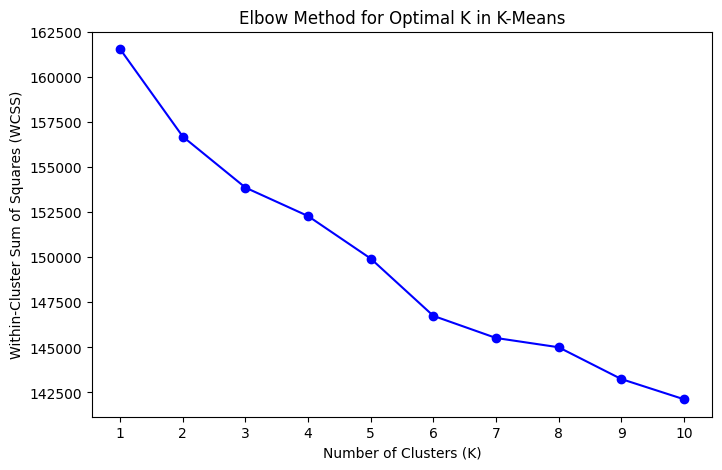

In [ ]:
# Calculate WCSS for a range of K values to use the Elbow Method
wcss = []
k_range = range(1, 11)  # Range of K values from 1 to 10

# Iterate through each k and calculate WCSS
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(processed_data_dataset)
    wcss.append(kmeans.inertia_)  # Inertia is the WCSS

# Plot the Elbow graph
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o', linestyle='-', color='b')
plt.title("Elbow Method for Optimal K in K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.xticks(k_range)
plt.show()


In [ ]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Define number of clusters for K-Means
n_clusters = 2

# Apply K-Means clustering
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
processed_data_dataset['KMeans_Cluster'] = kmeans.fit_predict(processed_data_dataset)

# Apply DBSCAN clustering
dbscan = DBSCAN(eps=0.5, min_samples=5)
processed_data_dataset['DBSCAN_Cluster'] = dbscan.fit_predict(processed_data_dataset)

# PCA for 2D visualization
pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(processed_data_dataset.drop(columns=['KMeans_Cluster', 'DBSCAN_Cluster']))
processed_data_dataset['PCA1'] = pca_result[:, 0]
processed_data_dataset['PCA2'] = pca_result[:, 1]

# Calculate evaluation scores only if DBSCAN has more than one cluster
silhouette_kmeans = silhouette_score(processed_data_dataset.drop(columns=['KMeans_Cluster', 'DBSCAN_Cluster', 'PCA1', 'PCA2']),
                                     processed_data_dataset['KMeans_Cluster'])

# Check for the number of clusters in DBSCAN, DBSCAN assigns -1 to noise points, so we count unique labels
unique_dbscan_labels = len(set(processed_data_dataset['DBSCAN_Cluster']) - {-1})  # Exclude noise (-1) label
silhouette_dbscan = None
dbi_dbscan = None

if unique_dbscan_labels > 1:
    silhouette_dbscan = silhouette_score(processed_data_dataset.drop(columns=['KMeans_Cluster', 'DBSCAN_Cluster', 'PCA1', 'PCA2']),
                                         processed_data_dataset['DBSCAN_Cluster'])
    dbi_dbscan = davies_bouldin_score(processed_data_dataset.drop(columns=['KMeans_Cluster', 'DBSCAN_Cluster', 'PCA1', 'PCA2']),
                                      processed_data_dataset['DBSCAN_Cluster'])
else:
    print("DBSCAN has only one cluster or all points are labeled as noise, skipping DBSCAN evaluation.")

dbi_kmeans = davies_bouldin_score(processed_data_dataset.drop(columns=['KMeans_Cluster', 'DBSCAN_Cluster', 'PCA1', 'PCA2']),
                                  processed_data_dataset['KMeans_Cluster'])

# Print evaluation scores
print(f"Silhouette Score (K-Means): {silhouette_kmeans}")
if silhouette_dbscan is not None:
    print(f"Silhouette Score (DBSCAN): {silhouette_dbscan}")
else:
    print("Silhouette Score (DBSCAN): Not available")

if dbi_dbscan is not None:
    print(f"Davies-Bouldin Index (DBSCAN): {dbi_dbscan}")
else:
    print("Davies-Bouldin Index (DBSCAN): Not available")

print(f"Davies-Bouldin Index (K-Means): {dbi_kmeans}")

Silhouette Score (K-Means): 0.031015913798455818
Silhouette Score (DBSCAN): 0.4014070425860408
Davies-Bouldin Index (DBSCAN): 0.9629380992412812
Davies-Bouldin Index (K-Means): 5.654762832225837


DBSCAN (Density-Based Spatial Clustering of Applications with Noise) can label all data points as noise if the eps parameter is too small or the dataset does not contain sufficiently dense clusters. When this happens, the algorithm assigns all points to the same cluster or labels them as noise (-1), making it impossible to compute the evaluation metrics that require multiple clusters.

# **PCA**

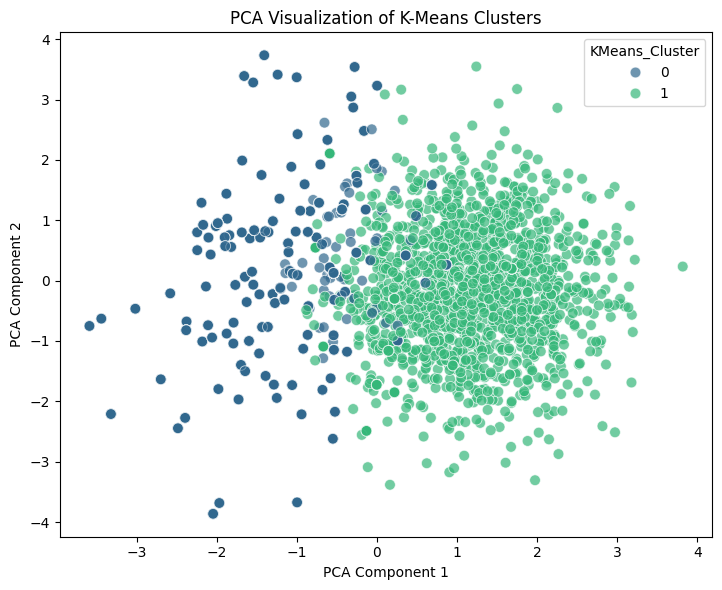

In [ ]:
# Plot PCA visualization for K-Means and DBSCAN clusters
plt.figure(figsize=(14, 6))

# Plot for K-Means
plt.subplot(1, 2, 1)
sns.scatterplot(data=processed_data_dataset, x='PCA1', y='PCA2', hue='KMeans_Cluster', palette='viridis', s=60, alpha=0.7)
plt.title("PCA Visualization of K-Means Clusters")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")

plt.tight_layout()
plt.show()

# **GMM**

Silhouette Score (GMM): 0.02489225053238085
Davies-Bouldin Index (GMM): 4.412033516054281


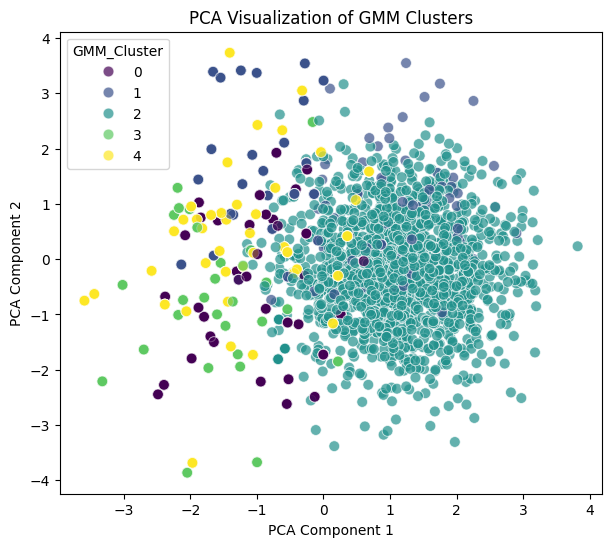

In [ ]:
from sklearn.mixture import GaussianMixture

# Apply Gaussian Mixture Model with the same number of clusters as K-Means (6 clusters)
gmm = GaussianMixture(n_components=5, random_state=42)
processed_data_dataset['GMM_Cluster'] = gmm.fit_predict(processed_data_dataset.drop(columns=['KMeans_Cluster', 'DBSCAN_Cluster', 'PCA1', 'PCA2']))

# Calculate silhouette and Davies-Bouldin scores for GMM
silhouette_gmm = silhouette_score(processed_data_dataset.drop(columns=['KMeans_Cluster', 'DBSCAN_Cluster', 'GMM_Cluster', 'PCA1', 'PCA2']),
                                  processed_data_dataset['GMM_Cluster'])
dbi_gmm = davies_bouldin_score(processed_data_dataset.drop(columns=['KMeans_Cluster', 'DBSCAN_Cluster', 'GMM_Cluster', 'PCA1', 'PCA2']),
                               processed_data_dataset['GMM_Cluster'])

# Print the evaluation scores for GMM
print(f"Silhouette Score (GMM): {silhouette_gmm}")
print(f"Davies-Bouldin Index (GMM): {dbi_gmm}")

# PCA visualization for GMM clusters
plt.figure(figsize=(7, 6))
sns.scatterplot(data=processed_data_dataset, x='PCA1', y='PCA2', hue='GMM_Cluster', palette='viridis', s=60, alpha=0.7)
plt.title("PCA Visualization of GMM Clusters")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

# **Visualization using t-SNE**

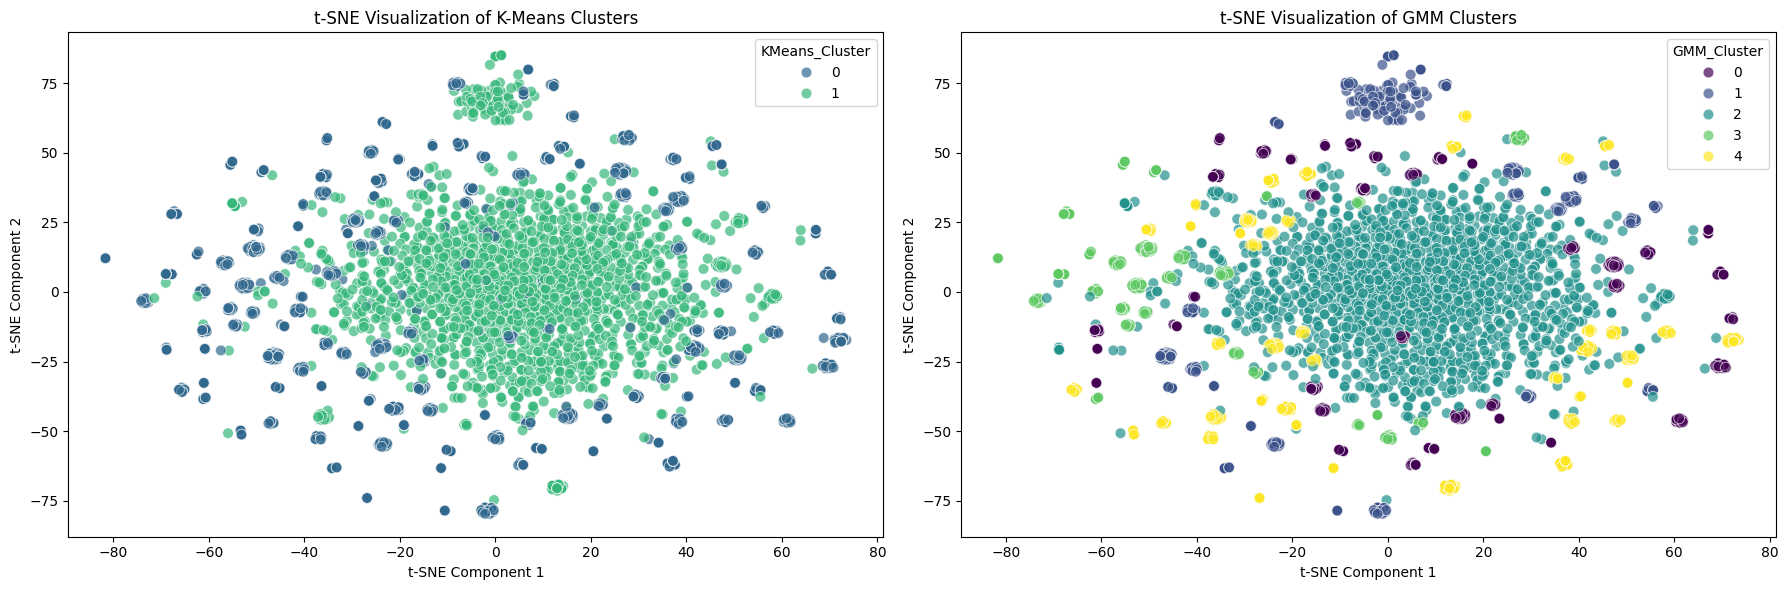

In [ ]:
from sklearn.manifold import TSNE

# Apply t-SNE for 2D visualization
tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(processed_data_dataset.drop(columns=['KMeans_Cluster', 'DBSCAN_Cluster', 'GMM_Cluster', 'PCA1', 'PCA2']))


# Add t-SNE results to the DataFrame
processed_data_dataset['tSNE1'] = tsne_result[:, 0]
processed_data_dataset['tSNE2'] = tsne_result[:, 1]

# Plot t-SNE visualization for K-Means, DBSCAN, and GMM clusters
plt.figure(figsize=(18, 6))

# Plot for K-Means
plt.subplot(1, 2, 1)
sns.scatterplot(data=processed_data_dataset, x='tSNE1', y='tSNE2', hue='KMeans_Cluster', palette='viridis', s=60, alpha=0.7)
plt.title("t-SNE Visualization of K-Means Clusters")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")

# Plot for GMM
plt.subplot(1, 2, 2)
sns.scatterplot(data=processed_data_dataset, x='tSNE1', y='tSNE2', hue='GMM_Cluster', palette='viridis', s=60, alpha=0.7)
plt.title("t-SNE Visualization of GMM Clusters")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")


plt.tight_layout()
plt.show()

# **Data Preprocessing and Feature Selection**

Handling Missing Values:

In [ ]:
# Check for missing values
print(dataset.isnull().sum())

PatientID                        0
Age                              0
Gender                           0
Ethnicity                        0
SocioeconomicStatus              0
EducationLevel                   0
BMI                              0
Smoking                          0
AlcoholConsumption               0
PhysicalActivity                 0
DietQuality                      0
SleepQuality                     0
FamilyHistoryKidneyDisease       0
FamilyHistoryHypertension        0
FamilyHistoryDiabetes            0
PreviousAcuteKidneyInjury        0
UrinaryTractInfections           0
SystolicBP                       0
DiastolicBP                      0
FastingBloodSugar                0
HbA1c                            0
SerumCreatinine                  0
BUNLevels                        0
GFR                              0
ProteinInUrine                   0
ACR                              0
SerumElectrolytesSodium          0
SerumElectrolytesPotassium       0
SerumElectrolytesCal

Drop irrelevant columns

In [ ]:
# Drop irrelevant columns
dataset.drop(columns=["DoctorInCharge"], inplace=True, errors='ignore')
dataset.drop(columns=["PatientID"], inplace=True, errors='ignore')


Initialize lists to store categorical and numerical columns

In [ ]:
categorical_columns = []
numerical_columns = []

# Loop through the columns and classify based on data type and unique values
for col in dataset.columns:
    if dataset[col].dtype == 'object'or dataset[col].nunique() <= 5:
        categorical_columns.append(col)
    else:
        numerical_columns.append(col)  # Numerical otherwise

# Display the results
print("Categorical Columns:")
print(categorical_columns)
print("\nNumerical Columns:")
print(numerical_columns)

Categorical Columns:
['Gender', 'Ethnicity', 'SocioeconomicStatus', 'EducationLevel', 'Smoking', 'FamilyHistoryKidneyDisease', 'FamilyHistoryHypertension', 'FamilyHistoryDiabetes', 'PreviousAcuteKidneyInjury', 'UrinaryTractInfections', 'ACEInhibitors', 'Diuretics', 'Statins', 'AntidiabeticMedications', 'Edema', 'HeavyMetalsExposure', 'OccupationalExposureChemicals', 'WaterQuality', 'Diagnosis']

Numerical Columns:
['Age', 'BMI', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'SystolicBP', 'DiastolicBP', 'FastingBloodSugar', 'HbA1c', 'SerumCreatinine', 'BUNLevels', 'GFR', 'ProteinInUrine', 'ACR', 'SerumElectrolytesSodium', 'SerumElectrolytesPotassium', 'SerumElectrolytesCalcium', 'SerumElectrolytesPhosphorus', 'HemoglobinLevels', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'NSAIDsUse', 'FatigueLevels', 'NauseaVomiting', 'MuscleCramps', 'Itching', 'QualityOfLifeScore', 'MedicalCheckupsFrequency', 'MedicationAdherence', 'He






Checking outlier

In [ ]:
def count_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return len(outliers)

# Check all numerical columns
for col in numerical_columns:
    num_outliers = count_outliers_iqr(dataset, col)
    print(f"{col}: {num_outliers} outliers found.")



Age: 0 outliers found.
BMI: 0 outliers found.
AlcoholConsumption: 0 outliers found.
PhysicalActivity: 0 outliers found.
DietQuality: 0 outliers found.
SleepQuality: 0 outliers found.
SystolicBP: 0 outliers found.
DiastolicBP: 0 outliers found.
FastingBloodSugar: 0 outliers found.
HbA1c: 0 outliers found.
SerumCreatinine: 0 outliers found.
BUNLevels: 0 outliers found.
GFR: 0 outliers found.
ProteinInUrine: 0 outliers found.
ACR: 0 outliers found.
SerumElectrolytesSodium: 0 outliers found.
SerumElectrolytesPotassium: 0 outliers found.
SerumElectrolytesCalcium: 0 outliers found.
SerumElectrolytesPhosphorus: 0 outliers found.
HemoglobinLevels: 0 outliers found.
CholesterolTotal: 0 outliers found.
CholesterolLDL: 0 outliers found.
CholesterolHDL: 0 outliers found.
CholesterolTriglycerides: 0 outliers found.
NSAIDsUse: 0 outliers found.
FatigueLevels: 0 outliers found.
NauseaVomiting: 0 outliers found.
MuscleCramps: 0 outliers found.
Itching: 0 outliers found.
QualityOfLifeScore: 0 outliers 

# **EDA Approach**

#**EDA(Exploratory Data Analysis)**

Unique values in each column

In [ ]:
# Unique values in each column
print("\nUnique Values per Column:")
for col in dataset.columns:
    print(f"{col}: {dataset[col].nunique()} unique values")


Unique Values per Column:
Age: 71 unique values
Gender: 2 unique values
Ethnicity: 4 unique values
SocioeconomicStatus: 3 unique values
EducationLevel: 4 unique values
BMI: 1659 unique values
Smoking: 2 unique values
AlcoholConsumption: 1659 unique values
PhysicalActivity: 1659 unique values
DietQuality: 1659 unique values
SleepQuality: 1659 unique values
FamilyHistoryKidneyDisease: 2 unique values
FamilyHistoryHypertension: 2 unique values
FamilyHistoryDiabetes: 2 unique values
PreviousAcuteKidneyInjury: 2 unique values
UrinaryTractInfections: 2 unique values
SystolicBP: 90 unique values
DiastolicBP: 60 unique values
FastingBloodSugar: 1659 unique values
HbA1c: 1659 unique values
SerumCreatinine: 1659 unique values
BUNLevels: 1659 unique values
GFR: 1659 unique values
ProteinInUrine: 1659 unique values
ACR: 1659 unique values
SerumElectrolytesSodium: 1659 unique values
SerumElectrolytesPotassium: 1659 unique values
SerumElectrolytesCalcium: 1659 unique values
SerumElectrolytesPhospho

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3048 entries, 0 to 3047
Data columns (total 52 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            3048 non-null   int64  
 1   Gender                         3048 non-null   int64  
 2   Ethnicity                      3048 non-null   int64  
 3   SocioeconomicStatus            3048 non-null   int64  
 4   EducationLevel                 3048 non-null   int64  
 5   BMI                            3048 non-null   float64
 6   Smoking                        3048 non-null   int64  
 7   AlcoholConsumption             3048 non-null   float64
 8   PhysicalActivity               3048 non-null   float64
 9   DietQuality                    3048 non-null   float64
 10  SleepQuality                   3048 non-null   float64
 11  FamilyHistoryKidneyDisease     3048 non-null   int64  
 12  FamilyHistoryHypertension      3048 non-null   i

class distribution

In [ ]:
# Check class distribution
print(dataset['Diagnosis'].value_counts(normalize=True))


Diagnosis
0    0.5
1    0.5
Name: proportion, dtype: float64


Basic Information & Summary Statistics




In [ ]:
print(dataset.info())

# Summary statistics
print(dataset.describe())

# Check unique values in categorical columns
print(dataset.nunique())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3048 entries, 0 to 3047
Data columns (total 52 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            3048 non-null   int64  
 1   Gender                         3048 non-null   int64  
 2   Ethnicity                      3048 non-null   int64  
 3   SocioeconomicStatus            3048 non-null   int64  
 4   EducationLevel                 3048 non-null   int64  
 5   BMI                            3048 non-null   float64
 6   Smoking                        3048 non-null   int64  
 7   AlcoholConsumption             3048 non-null   float64
 8   PhysicalActivity               3048 non-null   float64
 9   DietQuality                    3048 non-null   float64
 10  SleepQuality                   3048 non-null   float64
 11  FamilyHistoryKidneyDisease     3048 non-null   int64  
 12  FamilyHistoryHypertension      3048 non-null   i

Visualizing Numeric Data Distributions

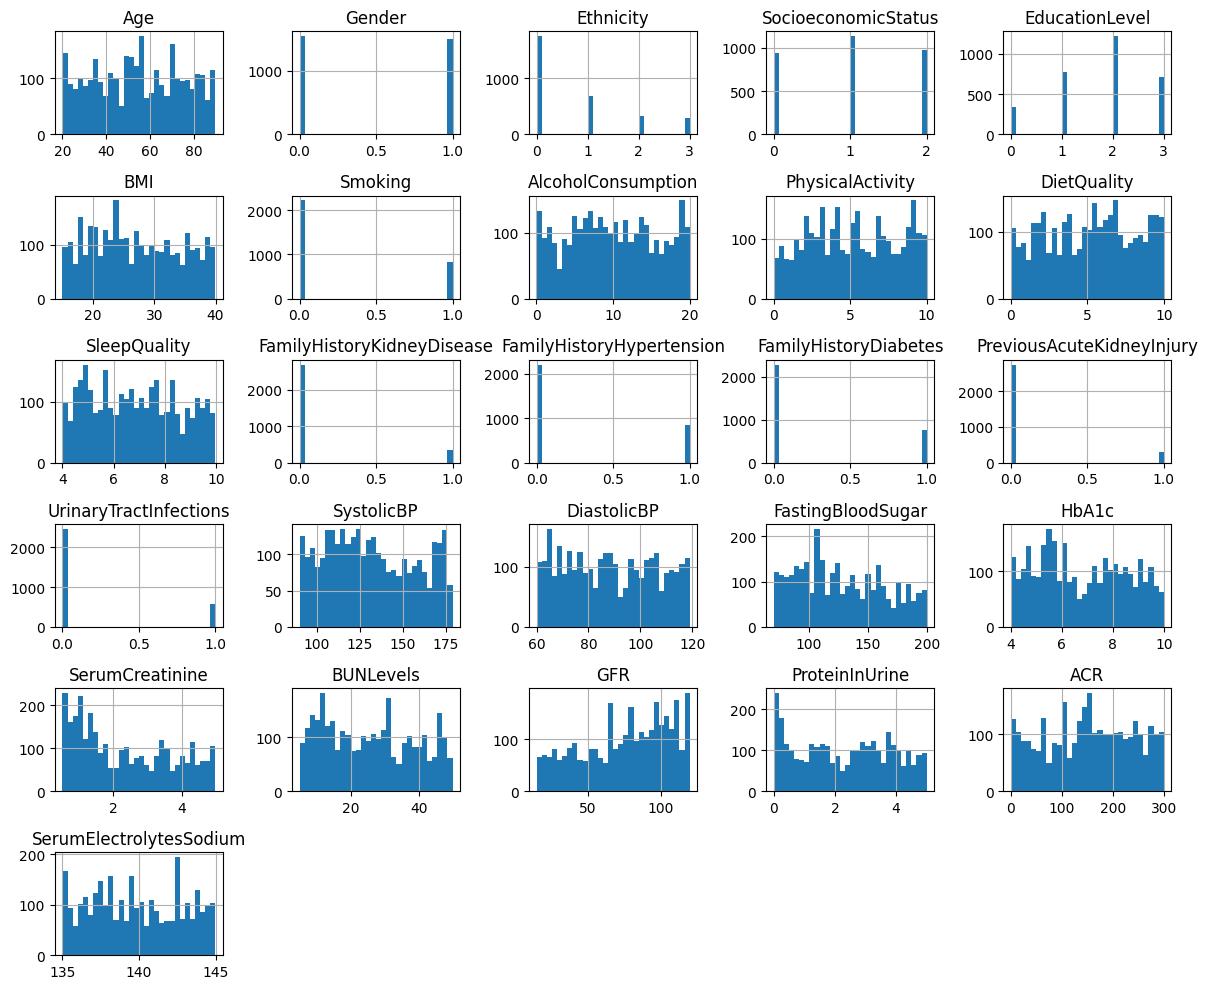

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

num_cols = dataset.select_dtypes(include=['number']).columns
half = len(num_cols) // 2
first_half_cols = num_cols[:half]

dataset[first_half_cols].hist(figsize=(12, 10), bins=30)
plt.tight_layout()
plt.show()

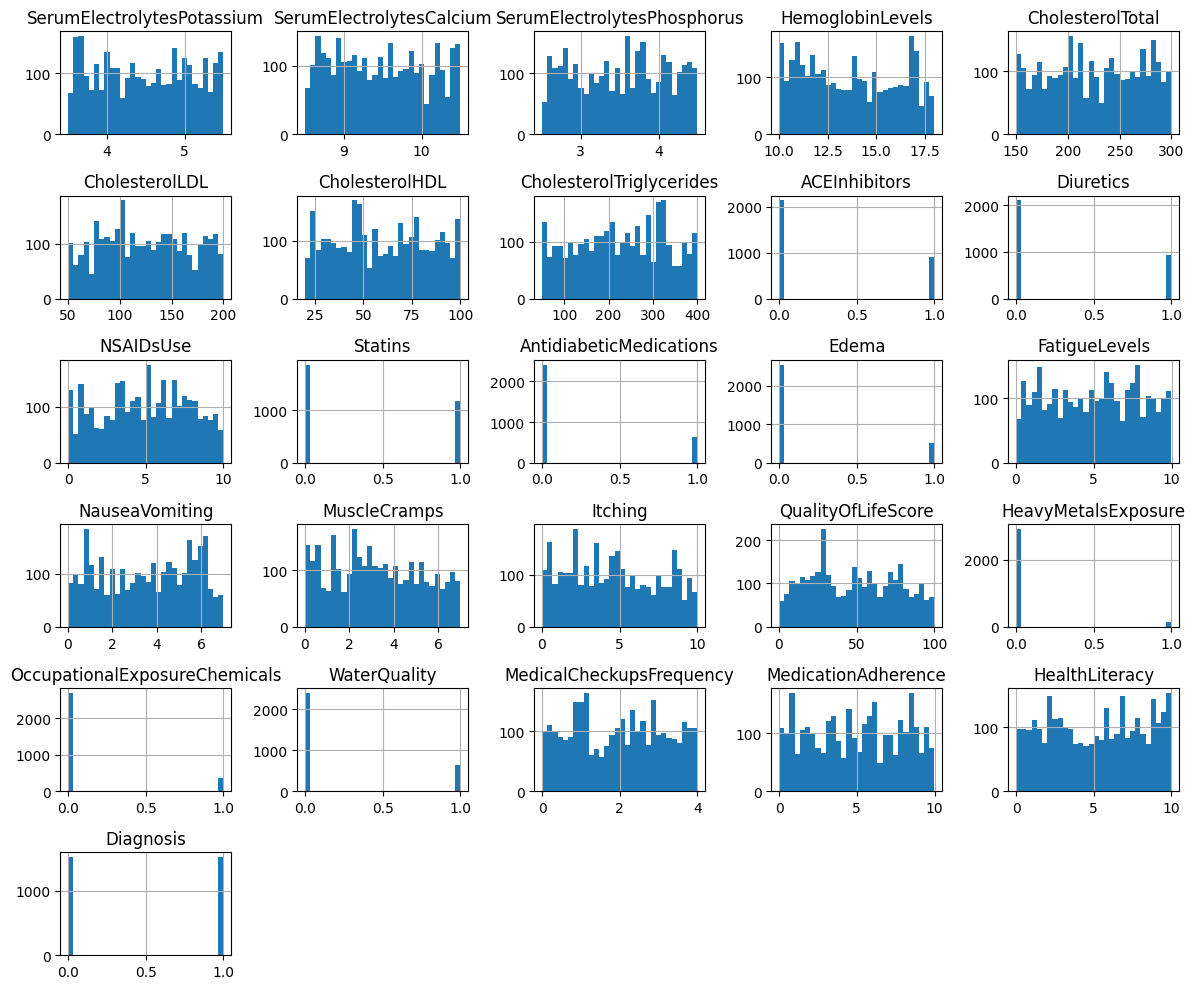

In [ ]:
num_cols = dataset.select_dtypes(include=['number']).columns
half = len(num_cols) // 2
second_half_cols = num_cols[half:]

dataset[second_half_cols].hist(figsize=(12, 10), bins=30)
plt.tight_layout()
plt.show()


Boxplots to Check Spread of Features

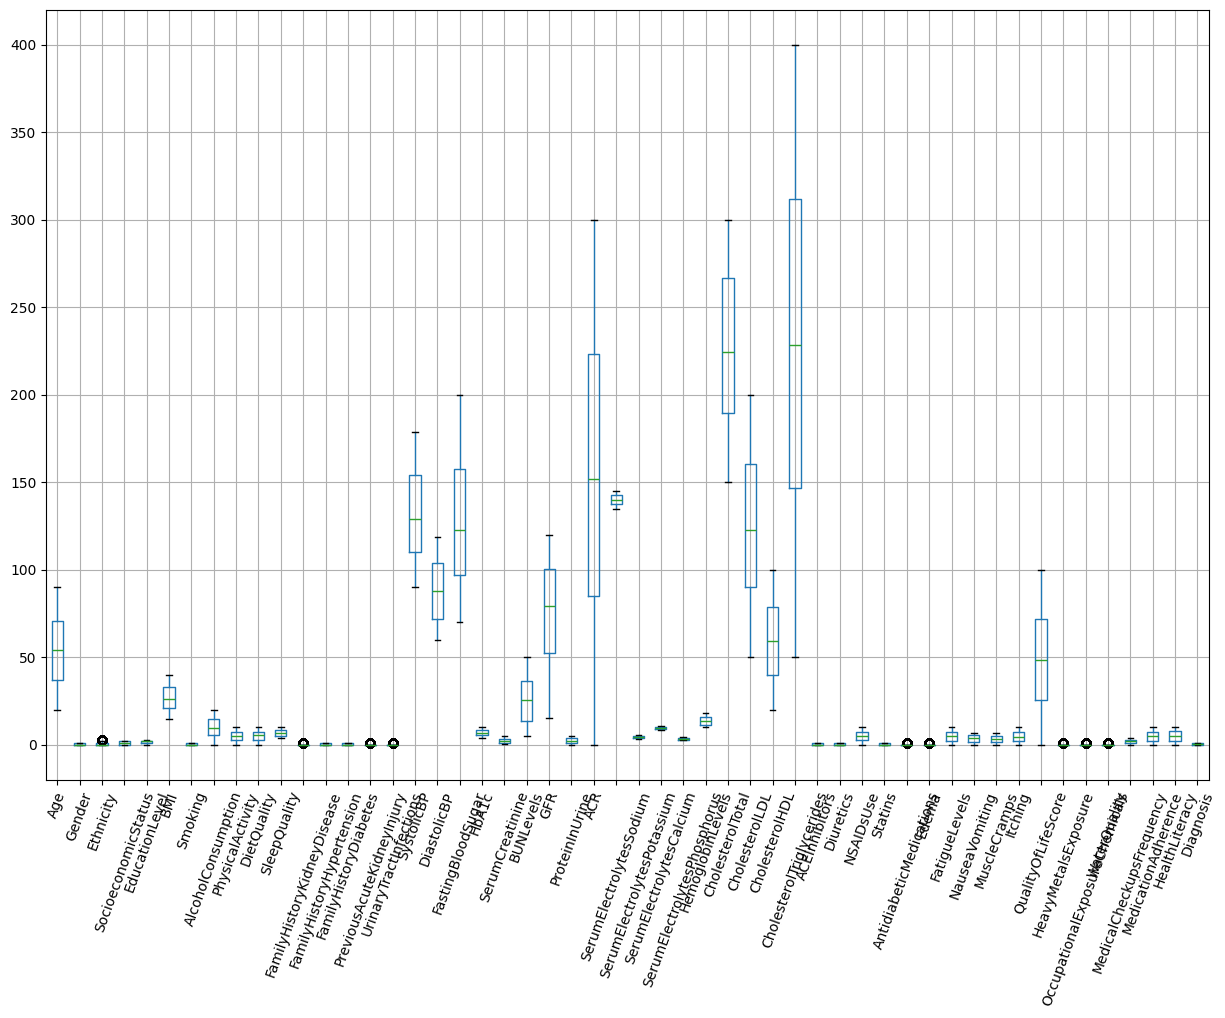

In [ ]:
plt.figure(figsize=(15, 10))
dataset.boxplot(rot=70)
plt.show()

Count Plots for Categorical Variables

In [ ]:
categorical_cols = dataset.select_dtypes(include=['object']).columns

for col in categorical_cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=dataset[col])
    plt.xticks(rotation=45)
    plt.show()

<Figure size 1800x600 with 0 Axes>

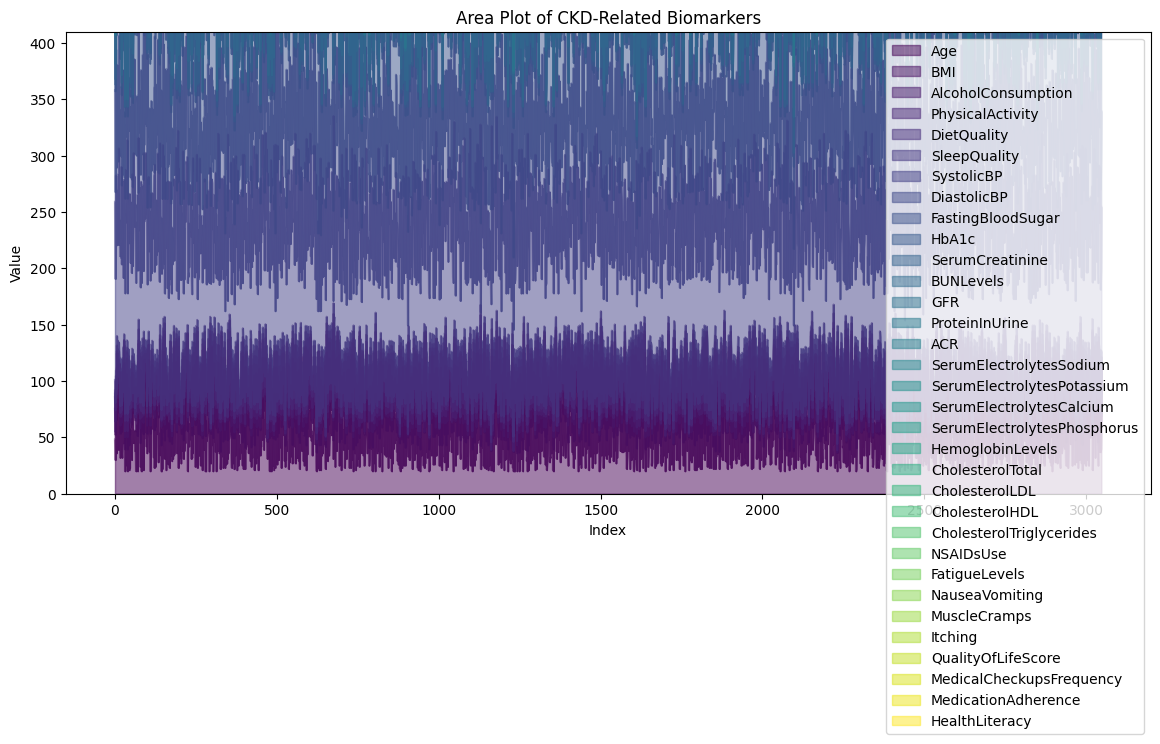

In [ ]:
import matplotlib.pyplot as plt



# Drop rows with any negative values in selected columns
df_area = dataset[numerical_columns].copy()
df_area = df_area[df_area[numerical_columns].ge(0).all(axis=1)]  # Keep rows where all selected columns are >= 0

# Create the area plot
plt.figure(figsize=(18, 6))
df_area.plot(kind='area', stacked=True, alpha=0.5, figsize=(14, 6), colormap='viridis')

# Add title and labels
plt.title('Area Plot of CKD-Related Biomarkers')
plt.xlabel('Index')
plt.ylabel('Value')
plt.ylim(0, df_area.values.max() + 10)
plt.legend(loc='upper right')

# Show the plot
plt.show()



Checking Feature Importance (for Target Column Exists)

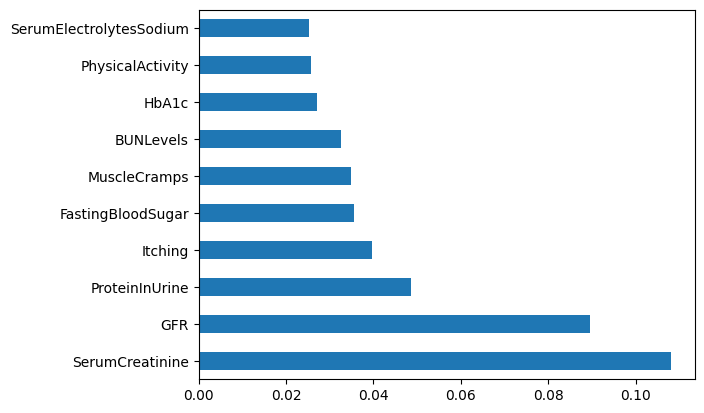

In [ ]:
# Change 'target_column' to actual target column name
X = dataset.drop(columns=['Diagnosis'])
y = dataset['Diagnosis']

# Encode categorical variables (if not done)
X = pd.get_dummies(X, drop_first=True)

# Fit model
rf = RandomForestClassifier()
rf.fit(X, y)

# Feature importance plot
feat_importances = pd.Series(rf.feature_importances_, index=X.columns)
feat_importances.nlargest(10).plot(kind='barh')
plt.show()

Data Distrubution

In [ ]:
for col in numerical_columns:
    stat, p = kstest(dataset[col], 'norm')
    print(f"{col}: p-value = {p}")

    if p > 0.05:
        print(f"{col} looks normal ✅\n")
    else:
        print(f"{col} is NOT normal ❌\n")


Age: p-value = 0.0
Age is NOT normal ❌

BMI: p-value = 0.0
BMI is NOT normal ❌

AlcoholConsumption: p-value = 0.0
AlcoholConsumption is NOT normal ❌

PhysicalActivity: p-value = 0.0
PhysicalActivity is NOT normal ❌

DietQuality: p-value = 0.0
DietQuality is NOT normal ❌

SleepQuality: p-value = 0.0
SleepQuality is NOT normal ❌

SystolicBP: p-value = 0.0
SystolicBP is NOT normal ❌

DiastolicBP: p-value = 0.0
DiastolicBP is NOT normal ❌

FastingBloodSugar: p-value = 0.0
FastingBloodSugar is NOT normal ❌

HbA1c: p-value = 0.0
HbA1c is NOT normal ❌

SerumCreatinine: p-value = 0.0
SerumCreatinine is NOT normal ❌

BUNLevels: p-value = 0.0
BUNLevels is NOT normal ❌

GFR: p-value = 0.0
GFR is NOT normal ❌

ProteinInUrine: p-value = 0.0
ProteinInUrine is NOT normal ❌

ACR: p-value = 0.0
ACR is NOT normal ❌

SerumElectrolytesSodium: p-value = 0.0
SerumElectrolytesSodium is NOT normal ❌

SerumElectrolytesPotassium: p-value = 0.0
SerumElectrolytesPotassium is NOT normal ❌

SerumElectrolytesCalcium

Scalling numerical columns unsing the StandardScaler

In [ ]:
# Initialize the StandardScaler
scaler = StandardScaler()

# Apply StandardScaler to numerical columns
dataset[numerical_columns] = scaler.fit_transform(dataset[numerical_columns])

print("Numerical columns standardized using StandardScaler.")
dataset[numerical_columns]


Numerical columns standardized using StandardScaler.


,Age,BMI,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,SystolicBP,DiastolicBP,FastingBloodSugar,HbA1c,...,CholesterolTriglycerides,NSAIDsUse,FatigueLevels,NauseaVomiting,MuscleCramps,Itching,QualityOfLifeScore,MedicalCheckupsFrequency,MedicationAdherence,HealthLiteracy
0,-0.322470,0.047447,0.103396,-0.864409,-0.843127,1.567136,1.012008,0.596193,-0.253451,-1.567036,...,0.625929,0.934044,0.309540,1.290271,-1.529422,0.223262,-1.016245,0.476421,-0.941430,0.618922
1,-1.220723,-0.642045,-1.293563,1.384315,1.618746,-0.045537,-0.849877,-0.646064,-1.052267,-0.468623,...,0.389007,1.691141,-0.396616,-0.602512,-0.069619,-1.544701,0.125950,-0.025650,0.444676,-1.247305
2,-0.272567,-0.116693,0.038416,-0.726958,-0.833405,-0.607541,-0.035302,1.386721,-1.201517,-0.939419,...,0.448173,0.010832,-0.480017,-1.307642,0.253894,-1.164821,0.960600,-1.141883,-0.516586,-1.425483
3,1.374230,-1.302574,-1.732156,-1.490334,-0.504290,-1.182645,1.593847,1.330255,0.098681,0.359928,...,-1.201336,1.799082,-1.299065,0.627843,-0.978539,-0.604389,-0.657686,-0.420014,1.138994,-1.080929
4,-0.272567,1.226699,-0.615112,0.588203,-0.433715,-1.243088,0.119855,-1.154261,-0.839644,1.731419,...,1.133344,-0.597615,-0.557907,-1.394074,-1.338643,-1.428427,1.549728,1.092300,-1.486347,-0.595474
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3043,0.625686,0.625160,-0.133430,-1.642385,-0.823035,1.169799,1.477479,-0.984862,-1.537922,1.255349,...,-0.212456,1.513569,0.458326,-1.593174,-1.208115,1.821852,-0.984173,-1.295335,-1.453210,0.086520
3044,0.176559,0.875644,1.046664,0.152736,0.180588,1.408008,1.012008,0.709126,1.261511,0.874255,...,-0.026761,1.091712,-1.294081,-0.393041,-1.532643,0.576018,-0.814009,0.142505,-0.620777,0.851631
3045,-0.871402,1.590245,-1.181453,-1.091623,-1.032143,-0.394027,-1.548084,0.031531,-1.073425,-0.603583,...,0.632936,-1.265091,-0.437435,0.420261,1.875982,-0.824778,0.085258,0.882372,-0.649062,0.148109
3046,-0.721693,-1.660538,0.575497,-1.043771,1.556700,0.019108,-0.811088,0.539727,1.834946,1.410828,...,0.367066,1.709408,0.901703,1.397611,-1.293862,0.946400,0.258806,-1.352407,-0.618028,-0.294571


Dataset Distribution

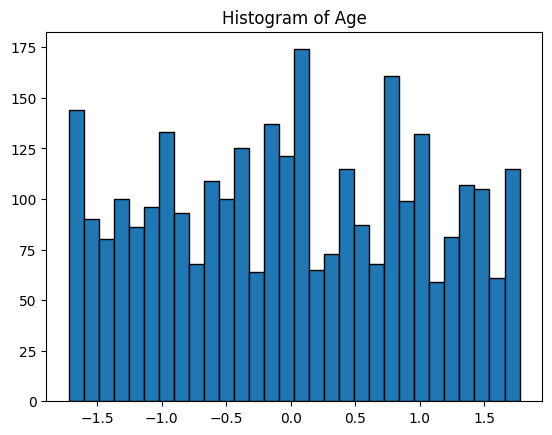

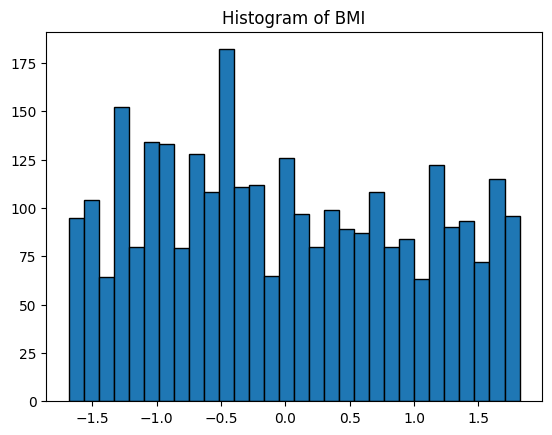

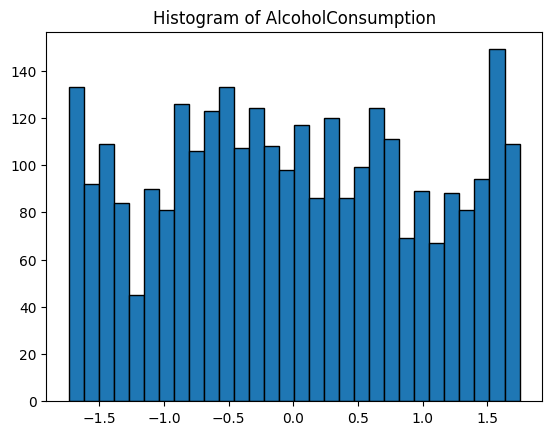

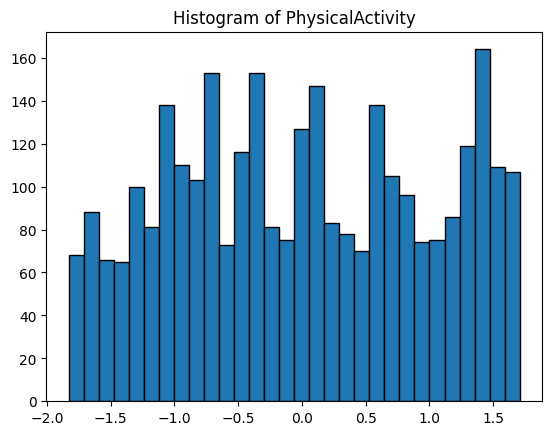

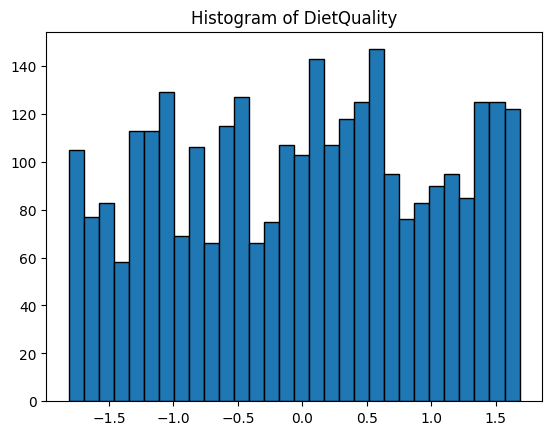

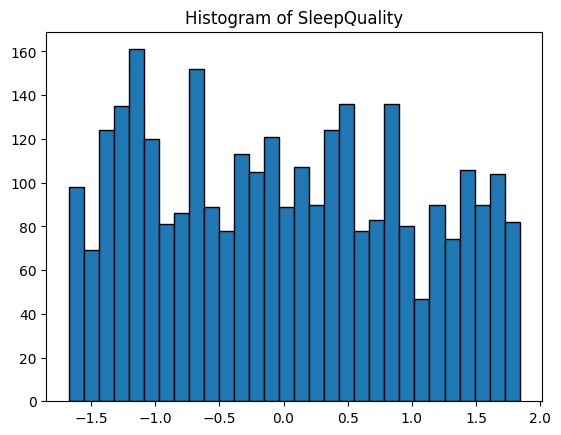

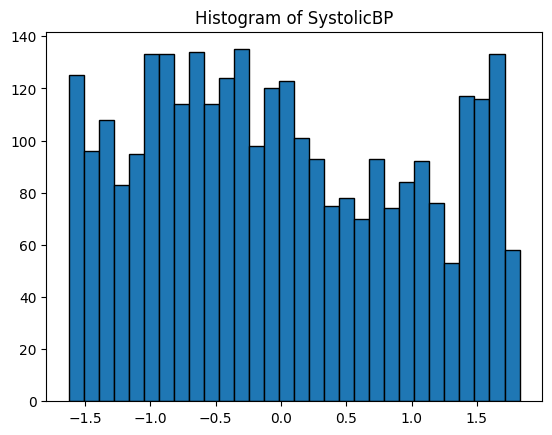

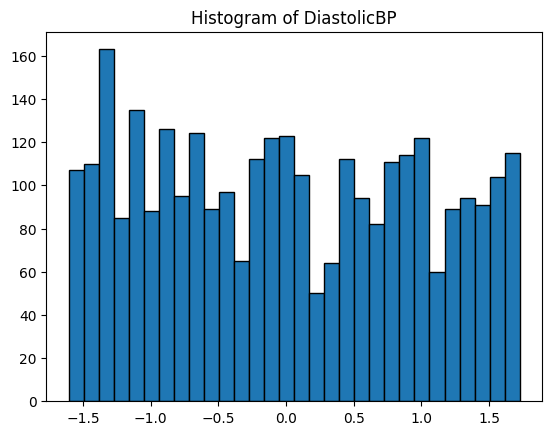

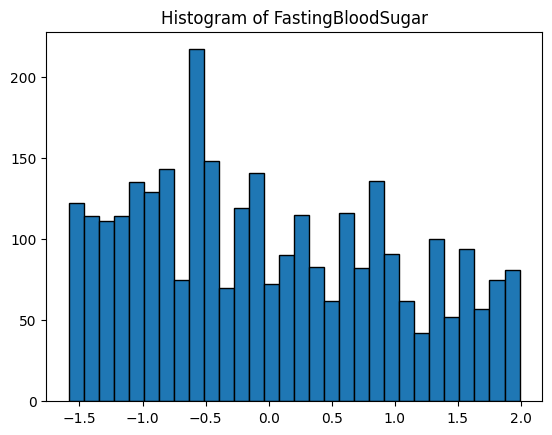

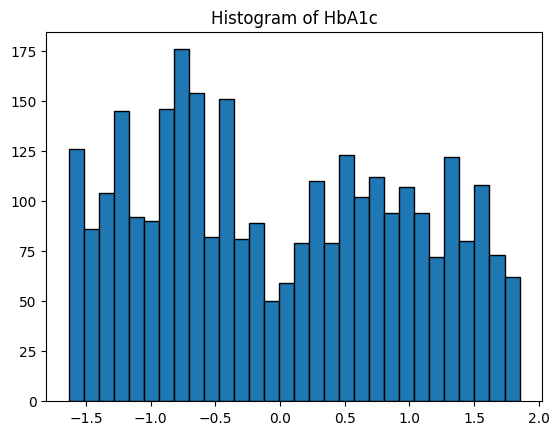

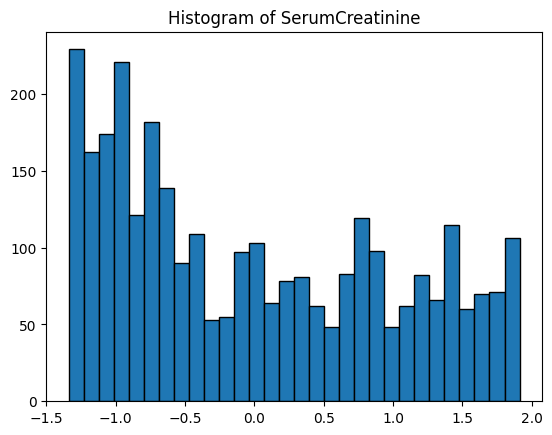

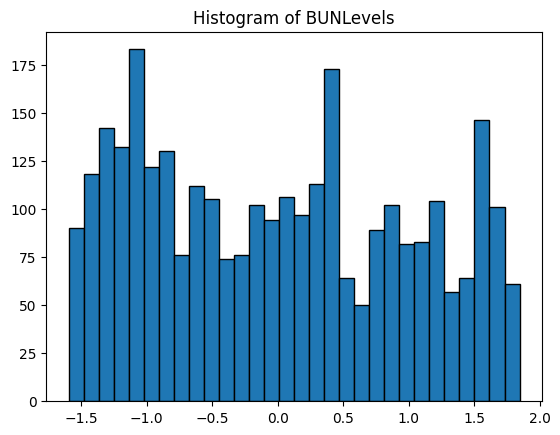

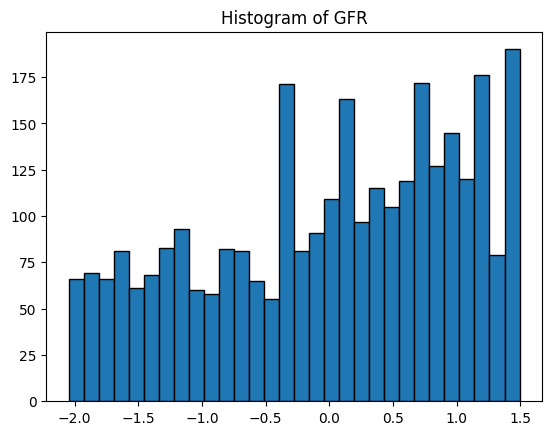

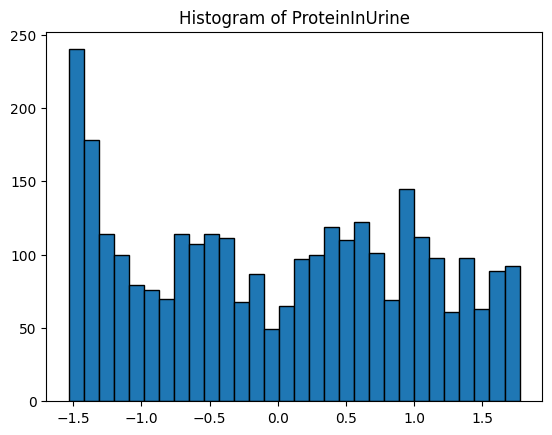

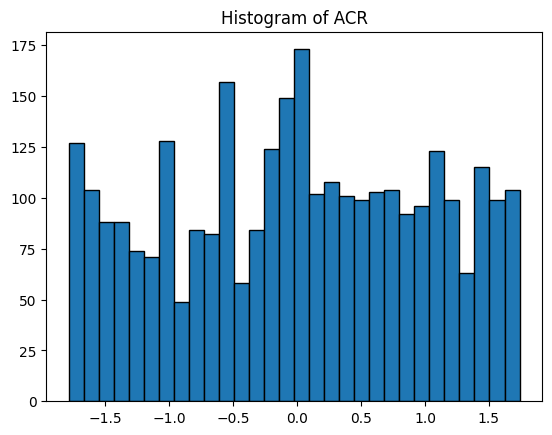

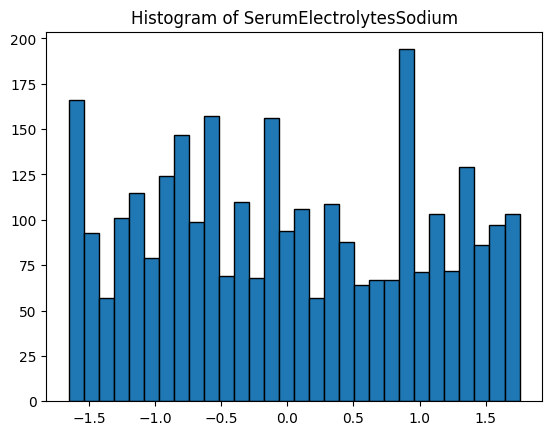

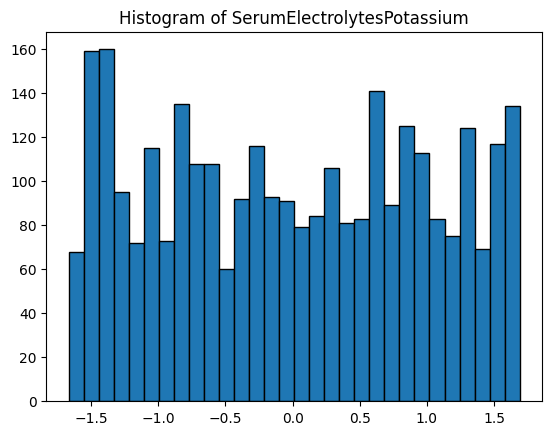

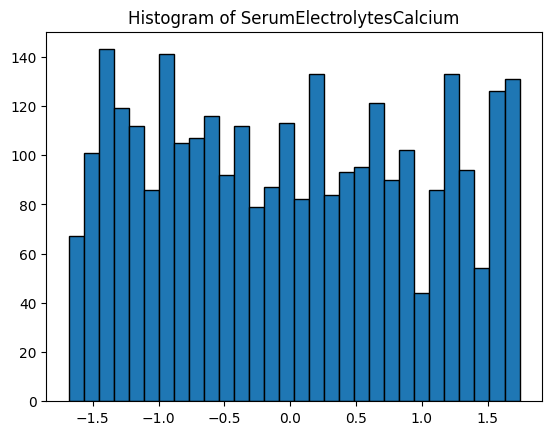

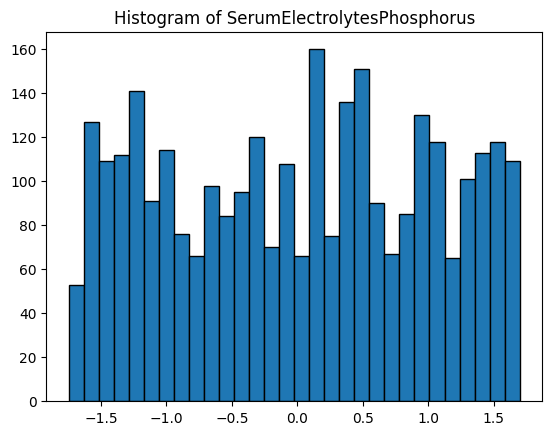

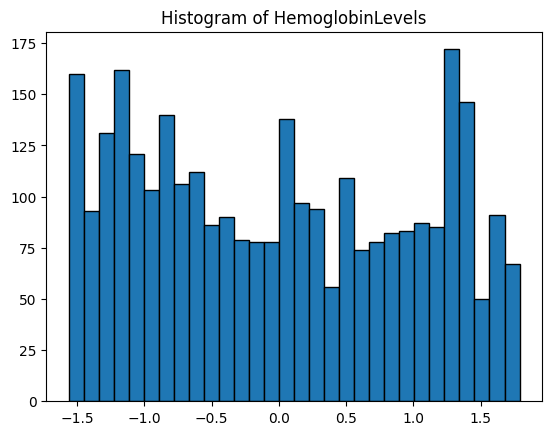

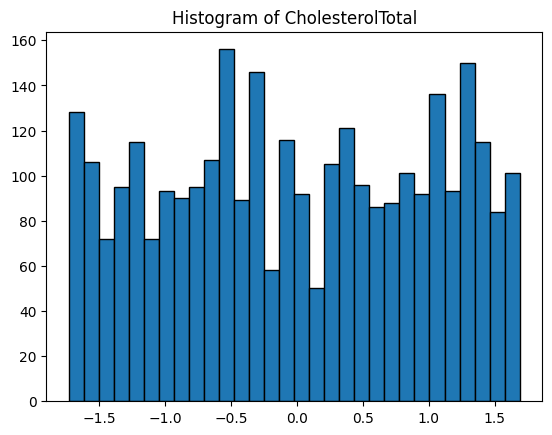

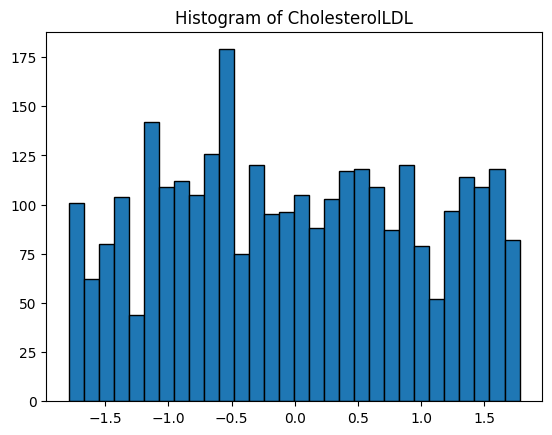

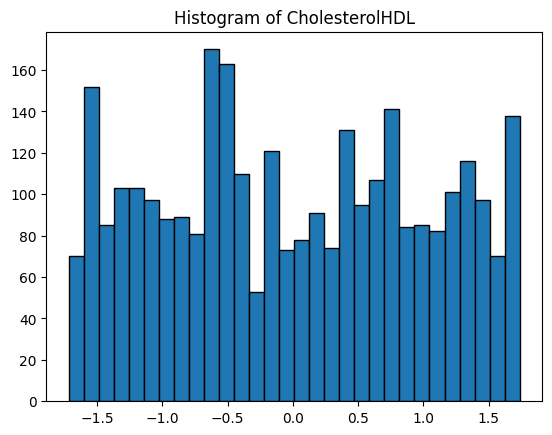

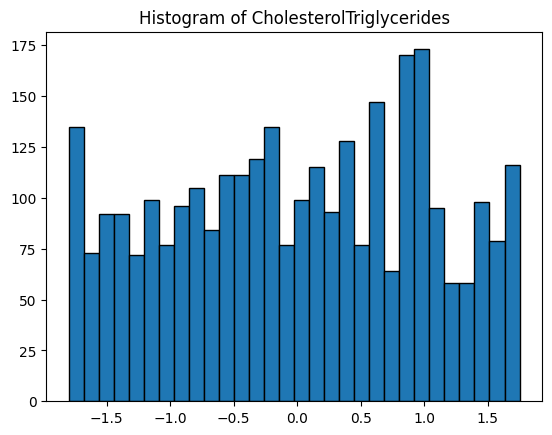

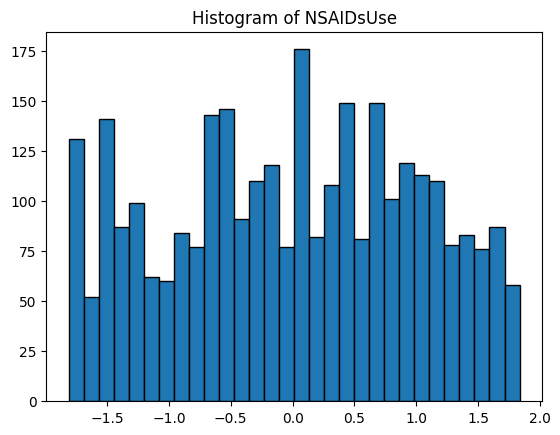

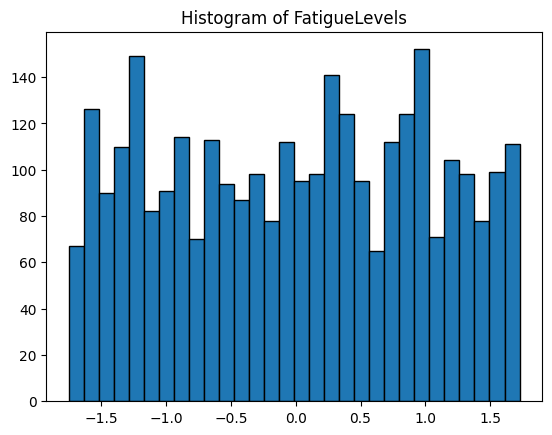

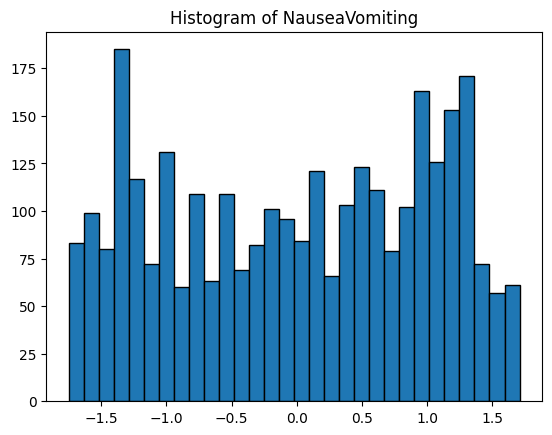

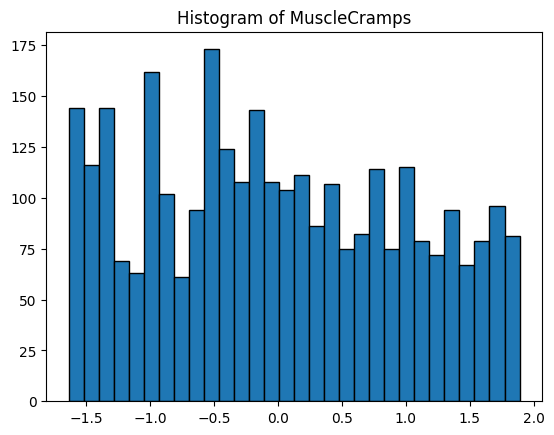

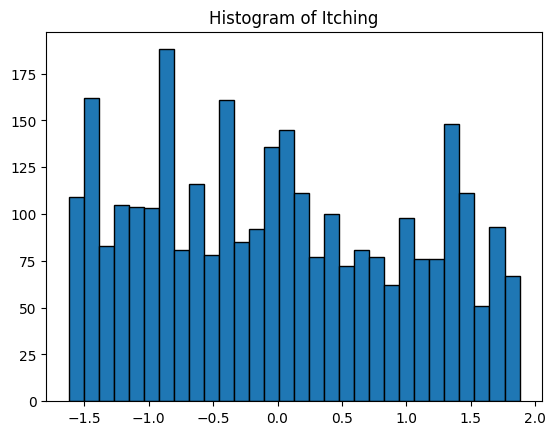

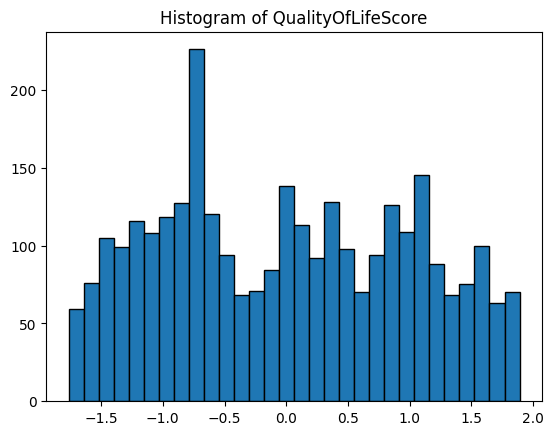

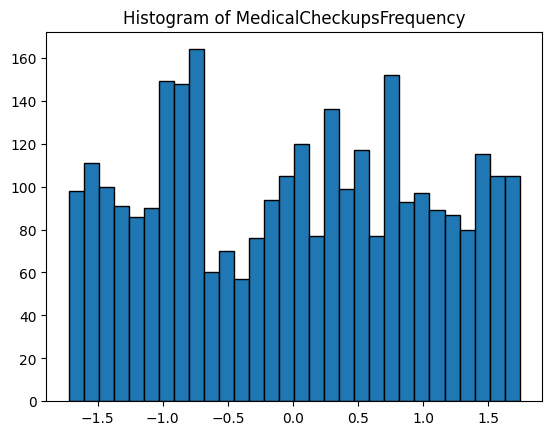

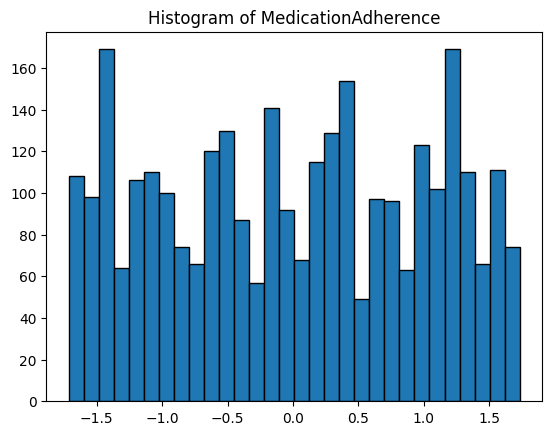

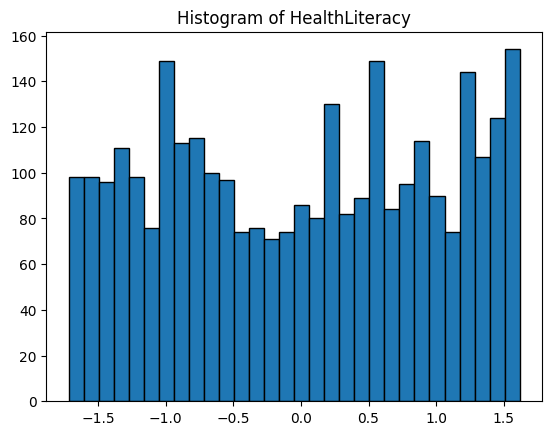

In [ ]:
import matplotlib.pyplot as plt

for col in numerical_columns:
    plt.hist(dataset[col], bins=30, edgecolor='k')
    plt.title(f"Histogram of {col}")
    plt.show()


In [ ]:
for col in categorical_columns:
    print(dataset[col].value_counts())

Gender
0    1542
1    1506
Name: count, dtype: int64
Ethnicity
0    1749
1     678
2     329
3     292
Name: count, dtype: int64
SocioeconomicStatus
1    1132
2     978
0     938
Name: count, dtype: int64
EducationLevel
2    1220
1     774
3     717
0     337
Name: count, dtype: int64
Smoking
0    2221
1     827
Name: count, dtype: int64
FamilyHistoryKidneyDisease
0    2692
1     356
Name: count, dtype: int64
FamilyHistoryHypertension
0    2205
1     843
Name: count, dtype: int64
FamilyHistoryDiabetes
0    2285
1     763
Name: count, dtype: int64
PreviousAcuteKidneyInjury
0    2737
1     311
Name: count, dtype: int64
UrinaryTractInfections
0    2462
1     586
Name: count, dtype: int64
ACEInhibitors
0    2141
1     907
Name: count, dtype: int64
Diuretics
0    2104
1     944
Name: count, dtype: int64
Statins
0    1869
1    1179
Name: count, dtype: int64
AntidiabeticMedications
0    2410
1     638
Name: count, dtype: int64
Edema
0    2544
1     504
Name: count, dtype: int64
HeavyMetalsExp

# **Hypothesis Setting**
1.   ***Null Hypothesis(H0):*** There is no relationship between Serum creatinine and diagnosis.
2.    ***Null Hypothesis (H0):*** There is no relationship between GFR levels and Diagnosis.
3.   ***Null Hypothesis(H0):*** There is no relationship between Alcohol consumption and diagnosis

4.   ***Null Hypothesis (H0):*** There is no relationship between Systolic blood pressure and diagnosis.
5.   ***Null Hypothesis(H0):***There is no relationship between  Smoking  and diagnosis.
6.   ***Null Hypothesis (H0):***There is no association between Muscle Cramps severity and CKD Diagnosis.
7.   ***Null Hypothesis (H0):***There is no association between FamilyHistoryKidneyDisease and Diagnosis.
8.   ***Null Hypothesis (H0):*** There is no association between HemoglobinLevels and Diagnosis.
9.   ***Null Hypothesis (H0):***There is no association between ProteinInUrine and Diagnosis.


# **Statistical Testing**
For the above hypothesis,the testing is chosen as follows:



*   t-test


*   ANOVA test-(One way ANOVA,Two way ANOVA)


*   Chi-square Test

*   Pearson Correlation






Null Hypothesis (H₀):There is no relationship between Serum creatinine and diagnosis.

In [ ]:
group_ckd = dataset[dataset['Diagnosis'] == 1]['SerumCreatinine']
group_non_ckd = dataset[dataset['Diagnosis'] == 0]['SerumCreatinine']

t_stat, p_val = ttest_ind(group_ckd, group_non_ckd, nan_policy='omit')
print("Test 7: Independent Samples t-Test (SerumCreatinine vs Diagnosis)")
print(f"T-statistic: {t_stat:.4f}, p-value: {p_val:.4f}")
print("Result:", "Reject Null Hypothesis (Significant)" if p_val < 0.05 else "Fail to Reject Null Hypothesis (Not significant)\n")


Test 7: Independent Samples t-Test (SerumCreatinine vs Diagnosis)
T-statistic: 20.3526, p-value: 0.0000
Result: Reject Null Hypothesis (Significant)


Null Hypothesis (H₀):There is no relationship between GFR levels and Diagnosis.

In [ ]:
group_ckd = dataset[dataset['Diagnosis'] == 1]['GFR']
group_non_ckd = dataset[dataset['Diagnosis'] == 0]['GFR']

t_stat, p_val = ttest_ind(group_ckd, group_non_ckd, nan_policy='omit')
print("Test 8: Independent Samples t-Test (GFR vs Diagnosis)")
print(f"T-statistic: {t_stat:.4f}, p-value: {p_val:.4f}")
print("Result:", "Reject Null Hypothesis (Significant)" if p_val < 0.05 else "Fail to Reject Null Hypothesis (Not significant)\n")


Test 8: Independent Samples t-Test (GFR vs Diagnosis)
T-statistic: -20.8604, p-value: 0.0000
Result: Reject Null Hypothesis (Significant)


Null Hypothesis (H₀): There is no relationship between Alcohol consumption and diagnosis

In [ ]:
group_ckd = dataset[dataset['Diagnosis'] == 1]['AlcoholConsumption']
group_non_ckd = dataset[dataset['Diagnosis'] == 0]['AlcoholConsumption']

t_stat, p_val = ttest_ind(group_ckd, group_non_ckd, nan_policy='omit')
print("Test 3: Independent Samples t-Test (AlcoholConsumption vs Diagnosis)")
print(f"T-statistic: {t_stat:.4f}, p-value: {p_val:.4f}")
print("Result:", "Reject Null Hypothesis (Significant)" if p_val < 0.05 else "Fail to Reject Null Hypothesis (Not significant)\n")


Test 3: Independent Samples t-Test (AlcoholConsumption vs Diagnosis)
T-statistic: -0.1518, p-value: 0.8794
Result: Fail to Reject Null Hypothesis (Not significant)



Null Hypothesis (H₀):There is no relationship between Systolic blood pressure and diagnosis.

In [ ]:
# Example: Systolic BP by Diagnosis groups (though usually used for >2 groups)
group_ckd = dataset[dataset['Diagnosis'] == 1]['SystolicBP']
group_non_ckd =  dataset[ dataset['Diagnosis'] == 0]['SystolicBP']

f_stat, p_val = f_oneway(group_ckd, group_non_ckd)
print("ANOVA Test (SystolicBP vs Diagnosis)")
print(f"F-statistic: {f_stat:.4f}, p-value: {p_val:.4f}")

if p_val < 0.05:
    print("Result: Reject Null Hypothesis (Significant difference)\n")
else:
    print("Result: Fail to Reject Null Hypothesis (No significant difference)\n")


ANOVA Test (SystolicBP vs Diagnosis)
F-statistic: 45.3559, p-value: 0.0000
Result: Reject Null Hypothesis (Significant difference)



In [ ]:
group_ckd = dataset[dataset['Diagnosis'] == 1]['SystolicBP']
group_non_ckd = dataset[dataset['Diagnosis'] == 0]['SystolicBP']

t_stat, p_val = ttest_ind(group_ckd, group_non_ckd, nan_policy='omit')
print("Test 7: Independent Samples t-Test (SystolicBP vs Diagnosis)")
print(f"T-statistic: {t_stat:.4f}, p-value: {p_val:.4f}")
print("Result:", "Reject Null Hypothesis (Significant)" if p_val < 0.05 else "Fail to Reject Null Hypothesis (Not significant)\n")


Test 7: Independent Samples t-Test (SystolicBP vs Diagnosis)
T-statistic: 6.7347, p-value: 0.0000
Result: Reject Null Hypothesis (Significant)


Null Hypothesis (H₀): There is no relationship between  Smoking  and diagnosis.

In [ ]:
# Example: Smoking vs Diagnosis
contingency_table = pd.crosstab(dataset['Smoking'], dataset['Diagnosis'])

chi2, p_val, dof, expected = chi2_contingency(contingency_table)
print("Chi-square Test (Smoking vs Diagnosis)")
print(f"Chi2 Statistic: {chi2:.4f}, p-value: {p_val:.4f}")

if p_val < 0.05:
    print("Result: Reject Null Hypothesis (Significant association)\n")
else:
    print("Result: Fail to Reject Null Hypothesis (No significant association)\n")


Chi-square Test (Smoking vs Diagnosis)
Chi2 Statistic: 9.5849, p-value: 0.0020
Result: Reject Null Hypothesis (Significant association)



Null Hypothesis (H₀):There is no association between Muscle Cramps severity and CKD Diagnosis.



In [ ]:
contingency = pd.crosstab(dataset['MuscleCramps'].round(), dataset['Diagnosis'])
chi_stat, p_val, _, _ = chi2_contingency(contingency)
print("Test 11: Chi-Square Test (MuscleCramps vs Diagnosis)")
print(f"Chi-square Statistic: {chi_stat:.4f}, p-value: {p_val:.4f}")
print("Result:", "Reject Null Hypothesis (Significant)" if p_val < 0.05 else "Fail to Reject Null Hypothesis (Not significant)\n")


Test 11: Chi-Square Test (MuscleCramps vs Diagnosis)
Chi-square Statistic: 93.0059, p-value: 0.0000
Result: Reject Null Hypothesis (Significant)


Null Hypothesis (H₀):There is no association between FamilyHistoryKidneyDisease and Diagnosis.

In [ ]:
contingency_table = pd.crosstab(dataset['FamilyHistoryKidneyDisease'], dataset['Diagnosis'])
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)

print("\nChi-square test results for Family History & CKD:")
print(f"Chi2: {chi2}, p-value: {p_value}")
if p_value < 0.05:
    print("Reject null hypothesis:There is  association between FamilyHistoryKidneyDisease and Diagnosis.")
else:
    print("Accept null hypothesis: There is no association between FamilyHistoryKidneyDisease and Diagnosis.")




Chi-square test results for Family History & CKD:
Chi2: 25.192421991084696, p-value: 5.188567210885977e-07
Reject null hypothesis:There is  association between FamilyHistoryKidneyDisease and Diagnosis.


Null Hypothesis (H₀):There is no association between HemoglobinLevels and Diagnosis.

In [ ]:
correlation, p_value = stats.pearsonr(dataset['HemoglobinLevels'], dataset['Diagnosis'])

print("\nPearson Correlation results for Hemoglobin Levels & CKD:")
print(f"Correlation: {correlation}, p-value: {p_value}")
if p_value < 0.05:
    print("Reject null hypothesis: There is  association between HemoglobinLevels and Diagnosis.")
else:
    print("Accept null hypothesis: There is no association between HemoglobinLevels and Diagnosis.")




Pearson Correlation results for Hemoglobin Levels & CKD:
Correlation: 0.09497407590623275, p-value: 1.4954275955647164e-07
Reject null hypothesis: There is  association between HemoglobinLevels and Diagnosis.


Null Hypothesis (H₀):There is no association between ProteinInUrine and Diagnosis.

In [ ]:
# ANOVA Test for Protein in Urine vs Diagnosis
group_ckd = dataset[dataset['Diagnosis'] == 1]['ProteinInUrine']
group_non_ckd = dataset[dataset['Diagnosis'] == 0]['ProteinInUrine']

f_stat, p_val = f_oneway(group_ckd, group_non_ckd)
print("ANOVA Test (Protein in Urine vs Diagnosis)")
print(f"F-statistic: {f_stat:.4f}, p-value: {p_val:.4f}")

if p_val < 0.05:
    print("Result: Reject Null Hypothesis There is association between ProteinInUrine and Diagnosis.")
else:
    print("Result: Accept Null Hypothesis:There is no association between ProteinInUrine and Diagnosis.")

ANOVA Test (Protein in Urine vs Diagnosis)
F-statistic: 62.7474, p-value: 0.0000
Result: Reject Null Hypothesis There is association between ProteinInUrine and Diagnosis.


# **Feature Engineering**

#**Correlation**

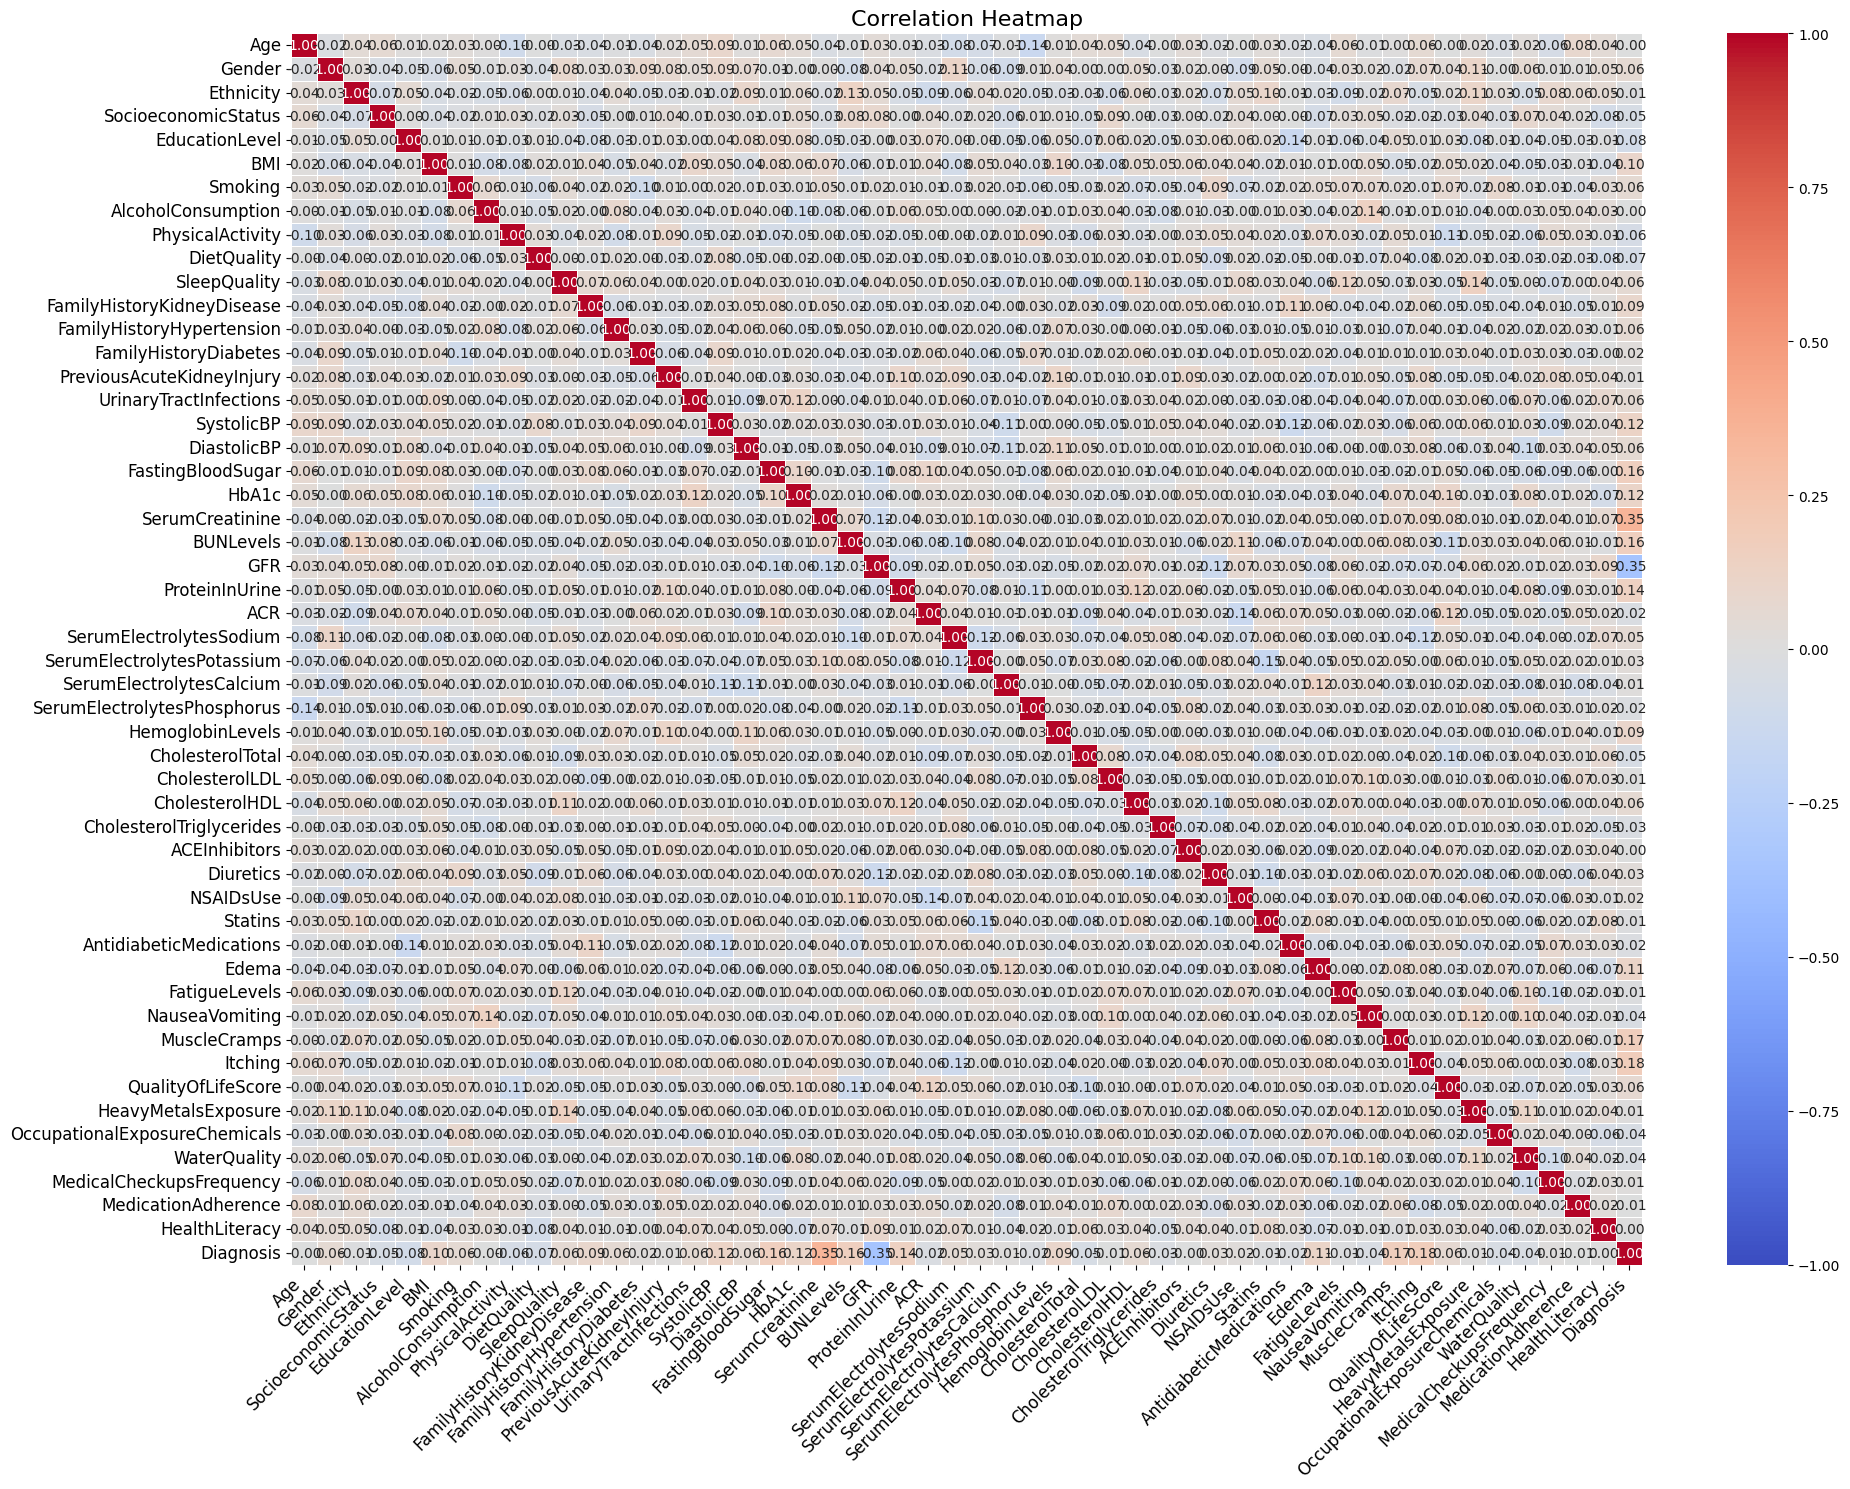

In [ ]:

# Calculate the correlation matrix
corr = dataset.corr()

# Set up the matplotlib figure
plt.figure(figsize=(20, 15))

# Draw the heatmap using seaborn
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5,annot_kws={"size": 10})

# Adjust layout for better visualization
plt.title('Correlation Heatmap', fontsize=16)
plt.xticks(rotation=45, ha='right',fontsize=12)
plt.yticks(rotation=0,fontsize=12)
plt.tight_layout()

# Show the plot
plt.show()

<ipython-input-40-44f7f820f4e1>:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=correlation_with_others.index, y=correlation_with_others.values, palette='coolwarm')


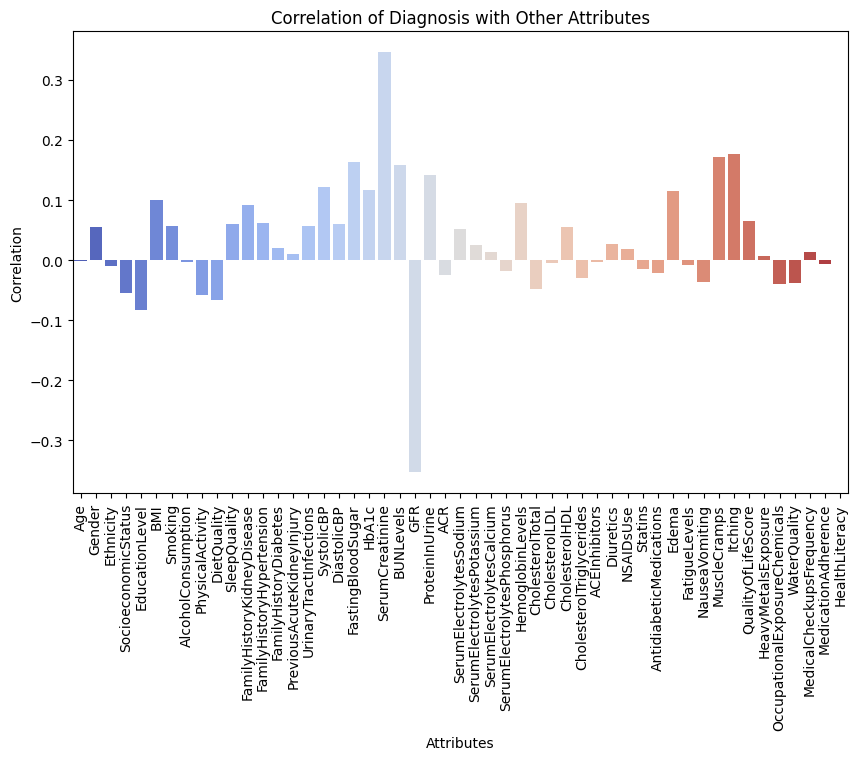

In [ ]:
# Choose the attribute to analyze
chosen_attribute = 'Diagnosis'  # Replace with your attribute name

# Check if the chosen attribute is in the DataFrame
if chosen_attribute not in dataset.columns:
    raise ValueError(f"{chosen_attribute} is not in the DataFrame")

# Compute the correlation of the chosen attribute with all other attributes
correlation_with_others = dataset.corr()[chosen_attribute]

# Drop the self-correlation (which is always 1) for plotting
correlation_with_others = correlation_with_others.drop(chosen_attribute)

# Plotting the correlations
plt.figure(figsize=(10, 6))
sns.barplot(x=correlation_with_others.index, y=correlation_with_others.values, palette='coolwarm')
plt.xticks(rotation=90)
plt.xlabel('Attributes')
plt.ylabel('Correlation')
plt.title(f'Correlation of {chosen_attribute} with Other Attributes')
plt.show()

In [ ]:
# Correlation with Diagnosis
print(corr['Diagnosis'].sort_values(ascending=False))

Diagnosis                        1.000000
SerumCreatinine                  0.345993
Itching                          0.176032
MuscleCramps                     0.171250
FastingBloodSugar                0.162626
BUNLevels                        0.157571
ProteinInUrine                   0.142071
SystolicBP                       0.121127
HbA1c                            0.116601
Edema                            0.114807
BMI                              0.099533
HemoglobinLevels                 0.094974
FamilyHistoryKidneyDisease       0.091935
QualityOfLifeScore               0.064598
FamilyHistoryHypertension        0.062345
SleepQuality                     0.060005
DiastolicBP                      0.059838
Smoking                          0.056815
UrinaryTractInfections           0.056613
Gender                           0.055122
CholesterolHDL                   0.055044
SerumElectrolytesSodium          0.051209
Diuretics                        0.026963
SerumElectrolytesPotassium       0

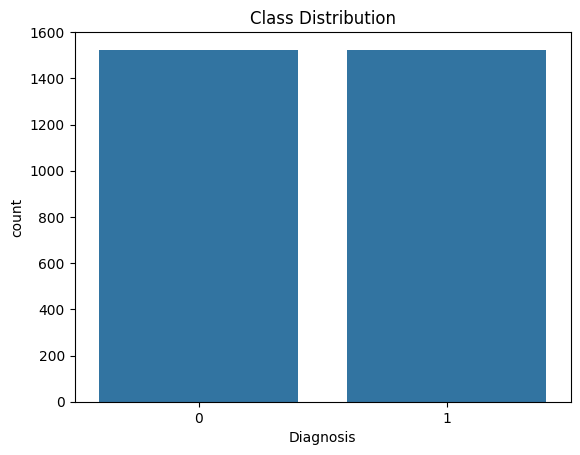

Diagnosis
0    0.5
1    0.5
Name: proportion, dtype: float64


In [ ]:
sns.countplot(x='Diagnosis', data=dataset)
plt.title("Class Distribution")
plt.show()

class_proportions = dataset['Diagnosis'].value_counts(normalize=True)
print(class_proportions)

# **Model Training & Testing**
We used five ML models for our dataset where we took every nutrient as independent variable in order to predict our CKD Diagnosis.



*   Random Forests
*   Support Vector Machine(SVM)

*   Neural Network(NN)
*   XGBoost
*   KNN Classifier

After making sure the features distinctively fit in the model, we predicted our desired CKD Diagnosis.

Classifying Diagnosis

Train-Test Split

In [ ]:

# Define features and target
X = dataset.drop(columns=['Diagnosis'])
y = dataset['Diagnosis']

# Split your dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Train-Test Split Done! ")
print(f"Training Set: {X_train.shape}, Testing Set: {X_test.shape}")


Train-Test Split Done! 
Training Set: (2133, 51), Testing Set: (915, 51)


In [ ]:
# Apply SMOTE to balance the training data
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Check the class distribution after applying SMOTE
print("Resampled class distribution:", Counter(y_train_resampled))



Resampled class distribution: Counter({1: 1081, 0: 1081})


*Model Train*

In [ ]:
def plot_roc_curve(y_test, y_scores, model_name):
    fpr, tpr, _ = roc_curve(y_test, y_scores)
    roc_auc = auc(fpr, tpr)
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {model_name}')
    plt.legend(loc="lower right")
    plt.show()


Decision Tree Performance:
[[443   0]
 [ 51 421]]
Accuracy: 0.9443
Precision: 1.0000
Recall: 0.8919
F1 Score: 0.9429


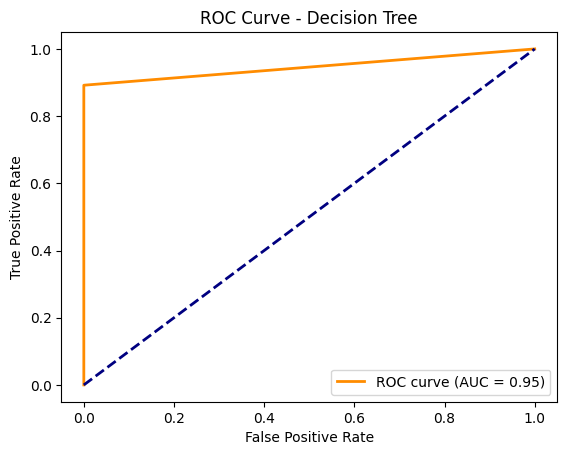

In [ ]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_scores = model.predict_proba(X_test)[:, 1]


print("Decision Tree Performance:")
print(confusion_matrix(y_test, y_pred))
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")

plot_roc_curve(y_test, y_scores, "Decision Tree")


Random Forest Performance:
[[443   0]
 [  2 470]]
Accuracy: 0.9978
Precision: 1.0000
Recall: 0.9958
F1 Score: 0.9979


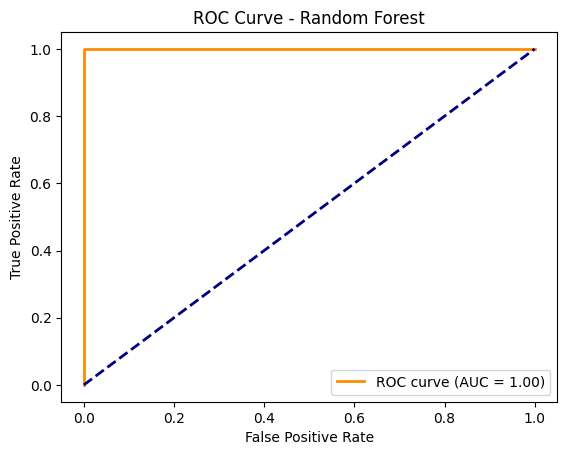

In [ ]:
model = RandomForestClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_scores = model.predict_proba(X_test)[:, 1]

print("Random Forest Performance:")
print(confusion_matrix(y_test, y_pred))
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")

plot_roc_curve(y_test, y_scores, "Random Forest")


SVM Performance:
[[443   0]
 [ 19 453]]
Accuracy: 0.9792
Precision: 1.0000
Recall: 0.9597
F1 Score: 0.9795


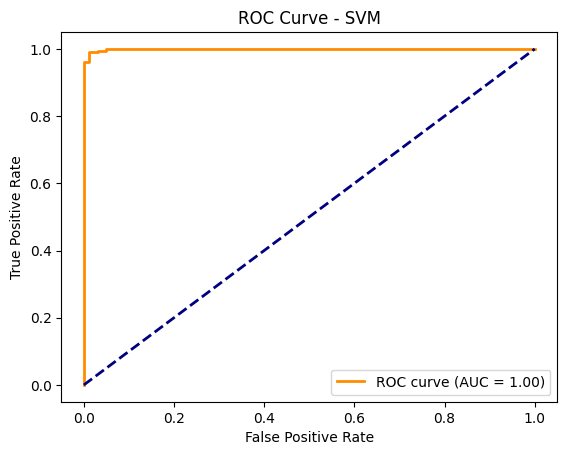

In [ ]:
model = SVC(probability=True)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_scores = model.predict_proba(X_test)[:, 1]

print("SVM Performance:")
print(confusion_matrix(y_test, y_pred))
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")

plot_roc_curve(y_test, y_scores, "SVM")


Neural Network Performance:
[[443   0]
 [ 28 444]]
Accuracy: 0.9694
Precision: 1.0000
Recall: 0.9407
F1 Score: 0.9694


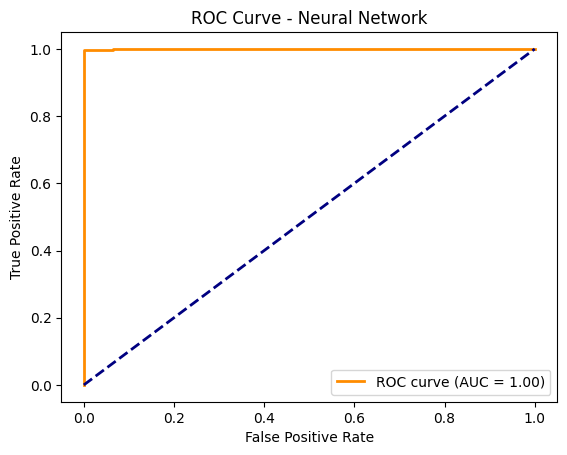

In [ ]:
model = MLPClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_scores = model.predict_proba(X_test)[:, 1]

print("Neural Network Performance:")
print(confusion_matrix(y_test, y_pred))
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")

plot_roc_curve(y_test, y_scores, "Neural Network")


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [13:52:13] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBoost Performance:
[[443   0]
 [ 11 461]]
Accuracy: 0.9880
Precision: 1.0000
Recall: 0.9767
F1 Score: 0.9882


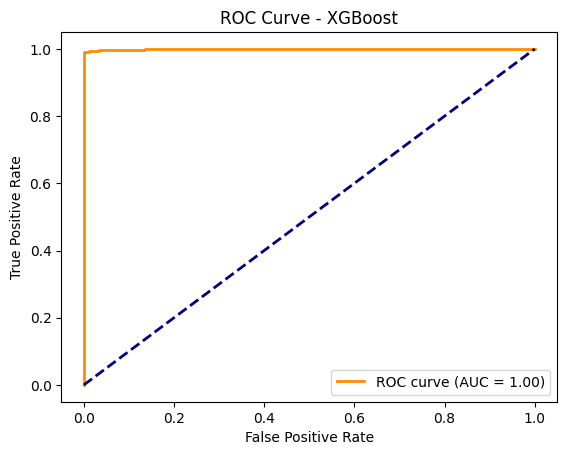

In [ ]:
model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_scores = model.predict_proba(X_test)[:, 1]

print("XGBoost Performance:")
print(confusion_matrix(y_test, y_pred))
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")

plot_roc_curve(y_test, y_scores, "XGBoost")


Logistic Regression Performance:
[[359  84]
 [106 366]]
Accuracy: 0.7923
Precision: 0.8133
Recall: 0.7754
F1 Score: 0.7939


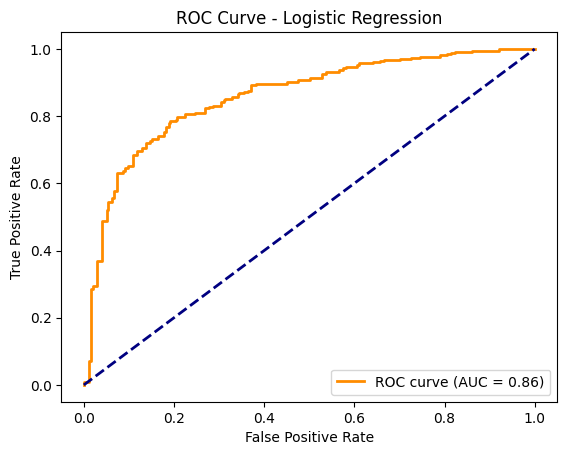

In [ ]:
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_scores = model.predict_proba(X_test)[:, 1]

print("Logistic Regression Performance:")
print(confusion_matrix(y_test, y_pred))
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")

plot_roc_curve(y_test, y_scores, "Logistic Regression")


KNN Classifier Performance:
[[434   9]
 [126 346]]
Accuracy: 0.8525
Precision: 0.9746
Recall: 0.7331
F1 Score: 0.8368


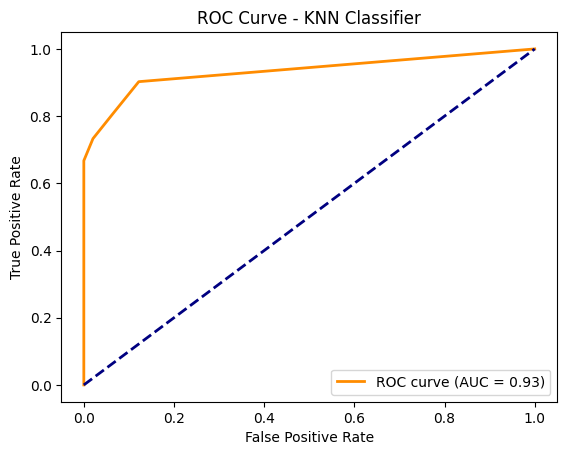

In [ ]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_scores = model.predict_proba(X_test)[:, 1]

print("KNN Classifier Performance:")
print(confusion_matrix(y_test, y_pred))
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")

plot_roc_curve(y_test, y_scores, "KNN Classifier")


Hyperparameter Tunning

In [ ]:
rf_param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

rf_random = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=rf_param_grid,
    n_iter=50,
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

rf_random.fit(X_train, y_train)
print("Random Forest best parameter:", rf_random.best_params_)

xgb_param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7, 10],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0]
}

xgb_random = RandomizedSearchCV(
    estimator=XGBClassifier(random_state=42),
    param_distributions=xgb_param_grid,
    n_iter=50,
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

xgb_random.fit(X_train, y_train)
print("XGBoost best parameter:", xgb_random.best_params_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Random Forest best parameter: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 30, 'bootstrap': False}
Fitting 5 folds for each of 50 candidates, totalling 250 fits


KeyboardInterrupt: 

In [ ]:
best_rf = RandomForestClassifier(
    n_estimators=300,
    min_samples_split=2,
    min_samples_leaf=2,
    max_depth=20,
    bootstrap=False,
    random_state=42
)

best_rf.fit(X_train, y_train)
y_pred_rf = best_rf.predict(X_test)


print("Optimized Random Forest Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-Score:", f1_score(y_test, y_pred_rf))


best_xgb = XGBClassifier(
    subsample=0.6,
    n_estimators=300,
    max_depth=3,
    learning_rate=0.2,
    colsample_bytree=0.6,
    random_state=42
)

best_xgb.fit(X_train, y_train)
y_pred_xgb = best_xgb.predict(X_test)


print("\nOptimized XGBoost Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1-Score:", f1_score(y_test, y_pred_xgb))

KeyboardInterrupt: 

In [ ]:
!pip install shap lime
!pip install shap --upgrade
import shap
import lime


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 3.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=ba5b0126f3953fa632120998b25f38bf4a0cd2c4dfd26f133c16f5adb2df1fce
  Stored in directory: /root/.cache/pip/wheels/85/fa/a3/9c2d44c9f3cd77cf4e533b58900b2bf4487f2a17e8ec212a3d
Successfully built lime


#Purposful Insights
After carefully identifying the essential features, we diligently integrated them into our selected models. Our primary objective was to seamlessly incorporate the independent variables into the model to extract valuable insights for our Diagnosis predictions. Subsequently, we determined that the random forest model offers the best fit for our Diagnosis predictions, closely followed by the XGBoost model

#**SHAP**

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [14:23:54] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


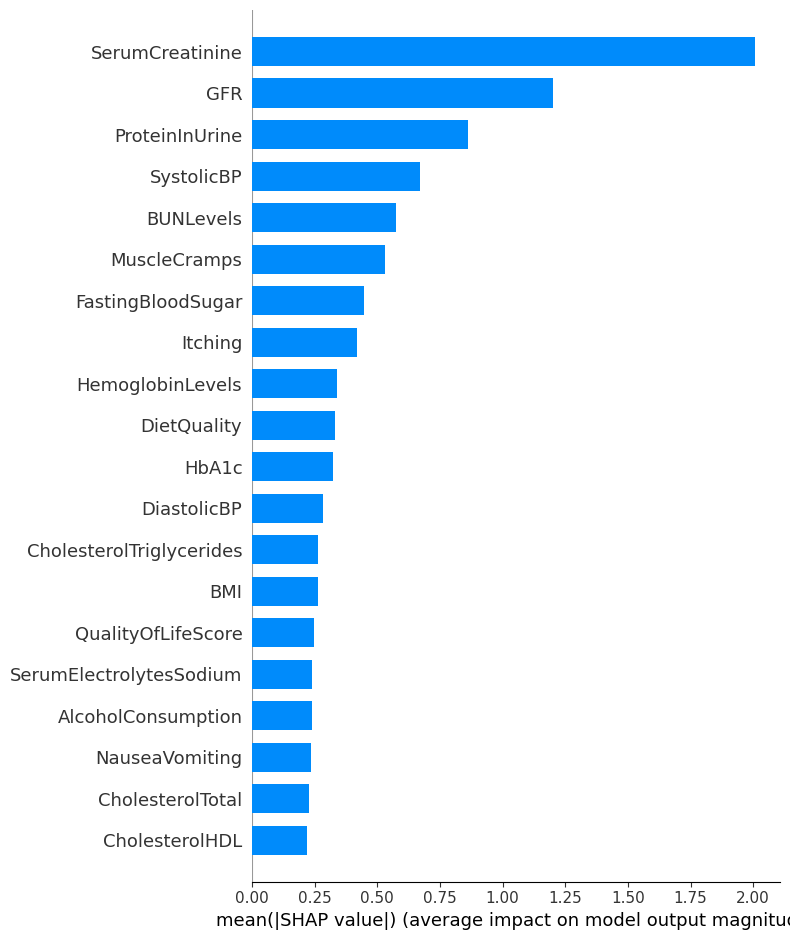

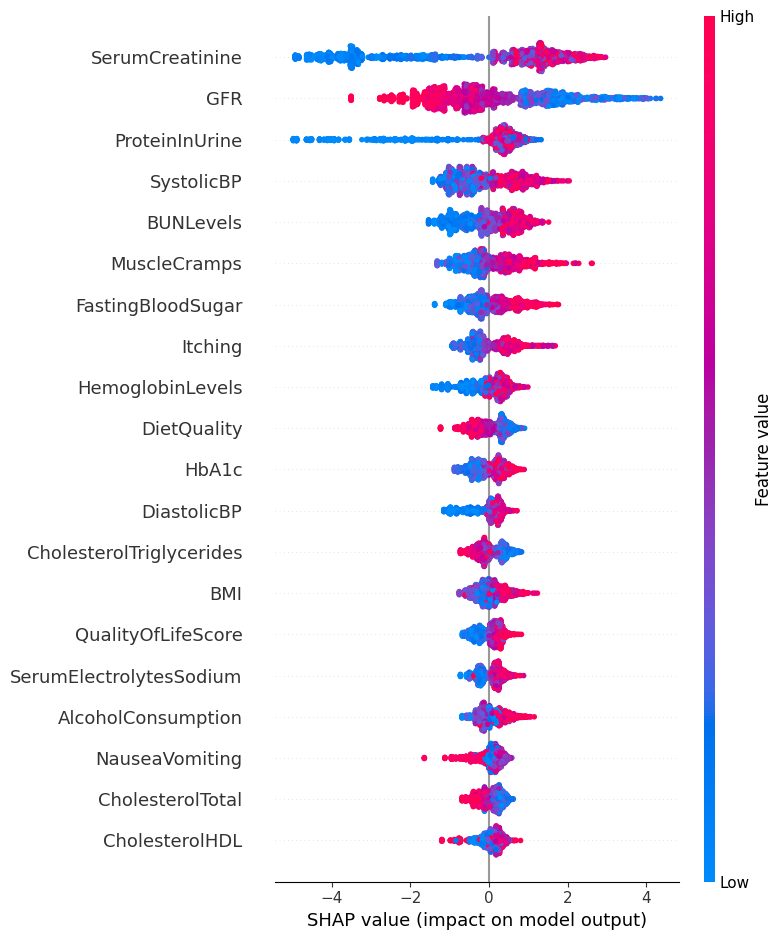

In [ ]:

# Assuming X_train and y_train are defined from previous cells
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss') # Initialize the model
xgb_model.fit(X_train, y_train) # Train the XGBoost model


# Create the SHAP explainer
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_train)

# Generate SHAP summary plot
shap.summary_plot(shap_values, X_train, plot_type="bar")

# You can also create a detailed SHAP summary plot (beeswarm plot) to see the distribution
shap.summary_plot(shap_values, X_train, plot_type='dot')

In [ ]:
!pip install --upgrade shap

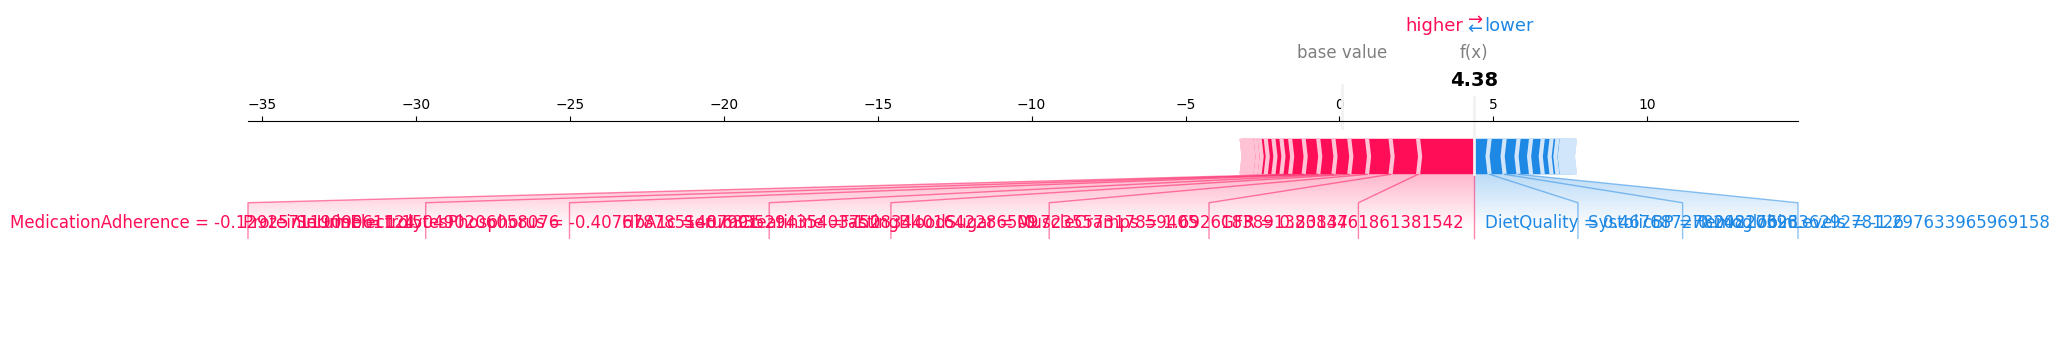

In [ ]:
sample_index = 0

expected_value = explainer.expected_value # Assuming binary classification

shap.force_plot(
    expected_value, # Pass the expected value for the class
    shap_values[sample_index], # Accessing shap values for the specific class
    X_test.iloc[sample_index],
    matplotlib=True,
)

#**LIME**

In [ ]:
from lime.lime_tabular import LimeTabularExplainer
import numpy as np

explainer = LimeTabularExplainer(
    training_data=np.array(X),  # Use X instead of X_train
    feature_names=X.columns,
    class_names=['Negative', 'Positive'],  # Adjust based on your target classes
    mode='classification'
)

sample_index = 0
exp = explainer.explain_instance(
    data_row=X_test.iloc[sample_index],
    predict_fn=xgb_model.predict_proba
)


exp.show_in_notebook(show_table=True, show_all=False)

/usr/local/lib/python3.11/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.11/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.11/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

# **PCA**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler







# Apply PCA (retain 95% variance)
pca = PCA(n_components=0.95)
principal_components = pca.fit_transform(dataset[numerical_columns])



# Convert PCA results into a DataFrame
pca_df = pd.DataFrame(principal_components, columns=[f'PC{i+1}' for i in range(principal_components.shape[1])])



# Add back the target variable "Diagnosis"
# Check if 'Diagnosis' exists in the original dataset before one-hot encoding
if 'Diagnosis' in dataset.columns:
    pca_df['Diagnosis'] = dataset['Diagnosis'].values
else:
    # If not found, try accessing the one-hot encoded columns (if they exist)
    diagnosis_cols = [col for col in dataset.columns if col.startswith('Diagnosis_')]
    if diagnosis_cols:
        # Assuming binary classification, use the column for the positive class
        pca_df['Diagnosis'] = dataset[diagnosis_cols[0]].values
    else:
        print("Warning: 'Diagnosis' column not found in dataset for PCA.")



        # Print explained variance ratio
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print(f"Number of Components Selected: {pca.n_components_}")


# Plot cumulative explained variance
plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', linestyle='--')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Explained Variance by PCA Components")
plt.grid()
plt.show()


# Show first few rows of transformed dataset
print(pca_df.head())

In [ ]:
# Apply PCA
pca = PCA()
pca_result = pca.fit_transform(dataset[numerical_columns])

# Create a DataFrame with PCA components
pca_df = pd.DataFrame(pca_result, columns=[f'PC{i+1}' for i in range(pca_result.shape[1])])

# Show the first few rows of the PCA result
print(pca_df.head())


        PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0 -0.984540  2.120104  1.490805 -2.115903 -1.112988  0.549744  1.477939   
1 -0.955474 -3.679786  0.368942 -0.809772 -1.355081 -0.546357 -0.664420   
2  0.853583  0.564130  2.035593 -1.534826  0.312111 -0.338591 -1.063208   
3 -0.454932  2.530067 -0.726761 -1.406334  1.463232 -0.651416 -1.709170   
4  2.823827 -2.250690  1.759274 -1.371386 -1.219628 -0.099914  0.190713   

        PC8       PC9      PC10  ...      PC24      PC25      PC26      PC27  \
0  2.878580 -0.412183  0.435180  ... -0.139928  0.212213  0.224101  0.522893   
1 -1.825748  0.485197  1.447276  ... -0.741076  0.768266  1.484841 -0.424687   
2  0.532242  0.161112 -0.908338  ... -1.848617 -0.809622 -0.518234 -0.344094   
3  0.317835  0.238552 -1.343210  ...  0.860524 -2.624526 -0.759933  0.177640   
4  1.592962  0.015998 -0.947606  ... -0.331406 -0.083358 -0.590288  0.336715   

       PC28      PC29      PC30      PC31      PC32      PC33  
0 -0